# 6강. Object Detection: 라벨링부터 Faster R-CNN, YOLO 직접 학습까지

**대상**: 파이썬과 1~5강 내용을 아는 입문자 · **분량**: 5교시 · **환경**: Google Colab

분류(classification)는 "이 사진에 무엇이 있는가"에 답합니다. 객체 탐지(object detection)는 한 걸음 더 나아가 "**무엇이 어디에 몇 개** 있는가"에 답합니다. 오늘은 데이터를 라벨링하는 일부터 시작해, 논문의 구조를 코드로 직접 조립하고, 마지막에는 내 데이터로 탐지기를 학습합니다.

오늘이 끝나면 다음을 할 수 있습니다.

- 바운딩 박스 형식(`xyxy`, `xywh`, YOLO)을 서로 변환하고 IoU와 NMS를 직접 계산한다.
- Roboflow 같은 도구로 라벨링한 COCO 형식 데이터를 `pycocotools`로 읽고 그린다.
- 박스 좌표까지 올바르게 변환하는 나만의 `Dataset`을 만든다.
- R-CNN, Fast R-CNN, Faster R-CNN이 무엇을 차례로 해결했는지 설명하고, Faster R-CNN을 torchvision 부품으로 조립해 학습한다.
- YOLO v1~v3의 아이디어를 설명하고 YOLOv3의 구조를 코드로 구현한다.
- `ultralytics` 패키지로 사전학습 모델을 추론하고 내 데이터로 전이학습한다.

| 교시 | 주제 | 다루는 내용 |
|---|---|---|
| 1교시 | Object Detection과 라벨 데이터 | 개념, 박스 형식, IoU, Roboflow, COCO 형식, pycocotools |
| 2교시 | 나만의 Dataset | COCO 데이터를 PyTorch `Dataset`과 `DataLoader`로 올리기 |
| 3교시 | R-CNN 계열 | R-CNN, Fast R-CNN, Faster R-CNN, RPN, NMS, Faster R-CNN 직접 구현과 학습 |
| 4교시 | YOLO | YOLO v1, v2, v3, FPN, YOLOv3 코드 구현 |
| 5교시 | YOLO 직접 써 보기 | ultralytics 추론, 내 데이터로 전이학습, 결과 확인 |

> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 학습이 빨라집니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.
>
> **용어**: 이 노트북에서 "원본"은 이 교재의 바탕이 된 **2023년 강의 노트북**을 뜻합니다. 고친 내용을 설명할 때 "원본"이라고 적습니다. 이 강의는 2023년판 4강과 5강의 일부를 합쳐 다시 구성했습니다.
>
> **계정이 없어도 됩니다.** 본 흐름은 누구나 내려받을 수 있는 공개 데이터 [Penn-Fudan 보행자 데이터](https://www.cis.upenn.edu/~jshi/ped_html/)(170장)로 진행합니다. Roboflow는 선택 실습입니다.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리
# imgaug는 NumPy 2에서 import부터 실패하므로(np.sctypes 제거) albumentations를 씁니다
%pip install -q ultralytics pycocotools albumentations natsort scikit-learn scikit-image tensorboard

import csv
import gc
import json
import os
import random
import shutil
import time
import urllib.request
import xml.etree.ElementTree as Et
import zipfile
from glob import glob
from pathlib import Path
from xml.etree.ElementTree import Element, ElementTree, SubElement

# 두 설정은 해당 라이브러리를 import하기 전에 정해야 적용됩니다
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"   # 버전 확인 메시지 끄기
os.environ["YOLO_VERBOSE"] = "False"           # 학습 로그가 노트북을 가득 채우지 않게 함. 자세히 보려면 True

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import skimage.io as io
import torch
import torch.nn as nn
import torchvision
import yaml
from matplotlib.patches import FancyBboxPatch, Rectangle
from natsort import natsorted
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torch.utils.tensorboard import SummaryWriter
from torchvision import transforms
from torchvision.models import VGG16_Weights, vgg16
from torchvision.ops import box_iou, nms, roi_pool
from torchvision.utils import draw_bounding_boxes, make_grid

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ device:", device)


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다. 1강에서 만든 함수입니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / device: mps


---
# 1교시. Object Detection과 라벨 데이터

## 1.1 Object Detection이란?

- 이미지 위에 있는 객체 주변에 **바운딩 박스(Bounding Box)** 를 만들고, 각 박스가 어떤 클래스인지 맞힙니다.
- 객체의 정확한 윤곽까지는 알 수 없지만(그것은 7강의 세그멘테이션이 합니다), 대략적인 위치와 개수를 알 수 있습니다.
- 객체 수 세기, 거리 측정, 속도 측정 등에 바로 쓰이고, 세밀한 분석을 하기 전에 관심 영역을 뽑는 단계로도 쓰입니다.

같은 사진을 두고 세 과제를 비교하면 차이가 분명합니다.

| 과제 | 출력 | 예 |
|---|---|---|
| 분류 | 이미지 전체에 클래스 하나 | "고양이" |
| 위치 찾기(Localization) | 객체 하나의 클래스와 박스 | "고양이, (10, 20, 80, 90)" |
| 객체 탐지 | 객체 **여러 개**의 클래스와 박스 | "고양이 (…), 개 (…), 오리 (…)" |

탐지가 어려운 까닭은 **출력 개수가 이미지마다 다르기** 때문입니다. 분류기는 출력 크기가 늘 같지만, 탐지기는 사람이 한 명인 사진과 스무 명인 사진에 서로 다른 개수의 박스를 내야 합니다. 앞으로 볼 모델들은 이 문제를 "일단 아주 많이 예측하고 나중에 걸러 낸다"는 방식으로 풉니다.

원본 자료의 비교 그림: [분류, 위치 찾기, 탐지 비교](https://images.velog.io/images/tataki26/post/0c67f497-de85-4751-9654-1485d71e083c/detection.png)

## 1.2 바운딩 박스 형식과 IoU

박스 하나는 숫자 4개로 적습니다. 그런데 **어떤 4개인지가 도구마다 다릅니다.** 탐지 코드 버그의 상당수가 여기서 나오므로 처음에 확실히 해 둡니다.

| 형식 | 4개 숫자 | 쓰는 곳 |
|---|---|---|
| `xyxy` | 왼쪽 위 x, y, 오른쪽 아래 x, y (픽셀) | Pascal VOC, torchvision |
| `xywh` | 왼쪽 위 x, y, 너비, 높이 (픽셀) | COCO |
| YOLO | **중심** x, y, 너비, 높이 (이미지 크기로 나눠 0~1) | YOLO 계열 |

예측한 박스가 정답과 얼마나 겹치는지는 **IoU(Intersection over Union)** 로 잽니다.

$$\text{IoU} = \frac{\text{겹친 넓이}}{\text{두 박스를 합친 넓이}}$$

완전히 겹치면 1, 전혀 안 겹치면 0입니다. 흔히 IoU가 0.5 이상이면 "맞췄다"고 칩니다. 아래 그림에서 숫자와 겹친 정도를 비교해 보세요. 생각보다 많이 겹쳐야 0.5가 됩니다.

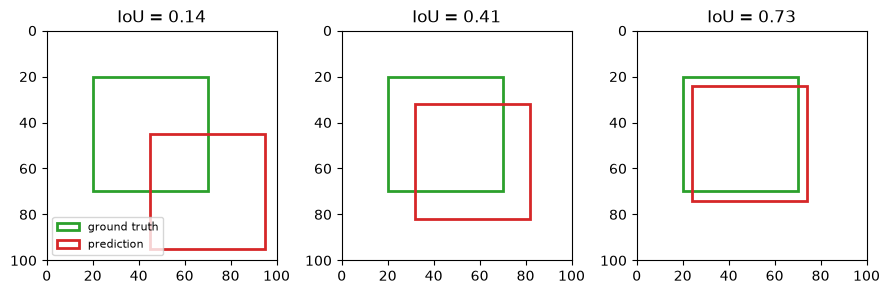

In [2]:
# 겹치는 정도에 따라 IoU가 어떻게 변하는지 그림으로 확인
gt_box = torch.tensor([[20.0, 20.0, 70.0, 70.0]])
pred_boxes = [
    torch.tensor([[45.0, 45.0, 95.0, 95.0]]),
    torch.tensor([[32.0, 32.0, 82.0, 82.0]]),
    torch.tensor([[24.0, 24.0, 74.0, 74.0]]),
]

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, pred in zip(axes, pred_boxes):
    for box, color, label in [(gt_box[0], "tab:green", "ground truth"), (pred[0], "tab:red", "prediction")]:
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=color, lw=2, label=label))
    ax.set_xlim(0, 100)
    ax.set_ylim(100, 0)   # 이미지 좌표는 y가 아래로 커진다
    ax.set_aspect("equal")
    ax.set_title(f"IoU = {box_iou(gt_box, pred).item():.2f}")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### 실습 1. 박스 형식 변환과 IoU

두 함수를 작성하세요. `xywh_to_xyxy`는 COCO 형식 박스를 `xyxy`로 바꾸고, `iou`는 `xyxy` 박스 두 개의 IoU를 돌려줍니다. 겹치지 않을 때 너비나 높이가 음수가 되지 않도록 주의하세요.

In [3]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def xywh_to_xyxy(box: list[float]) -> list[float]:
    """COCO의 [x, y, w, h]를 [x1, y1, x2, y2]로 바꿉니다."""
    x, y, w, h = box
    return [x, y, x + w, y + h]


def iou(box_a: list[float], box_b: list[float]) -> float:
    """xyxy 박스 두 개의 IoU를 계산합니다."""
    # 겹친 영역의 좌표: 왼쪽 위는 큰 쪽, 오른쪽 아래는 작은 쪽
    left, top = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    right, bottom = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    # 겹치지 않으면 너비나 높이가 음수가 되므로 0으로 자른다
    inter = max(0.0, right - left) * max(0.0, bottom - top)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    return inter / (area_a + area_b - inter)


assert xywh_to_xyxy([10, 20, 30, 40]) == [10, 20, 40, 60]
assert iou([0, 0, 10, 10], [20, 20, 30, 30]) == 0.0
assert iou([0, 0, 10, 10], [0, 0, 10, 10]) == 1.0
a, b = [20.0, 20.0, 70.0, 70.0], [32.0, 32.0, 82.0, 82.0]
assert abs(iou(a, b) - box_iou(torch.tensor([a]), torch.tensor([b])).item()) < 1e-6
print("IoU:", round(iou(a, b), 3))
```
</details>

## 1.3 Roboflow로 라벨링하기

탐지 모델을 학습하려면 "이 사진의 이 위치에 이 물체가 있다"는 **라벨**이 있어야 합니다. 라벨링은 대개 전용 도구로 합니다. [Roboflow](https://roboflow.com/)는 컴퓨터 비전 애플리케이션을 만들 수 있게 지원하는 서비스로, 여기서는 라벨링 도구로 씁니다.

**Universe**. [Roboflow Universe](https://universe.roboflow.com/)에는 다양한 무료 데이터셋이 모여 있습니다. 라이선스를 확인한 뒤 내려받아 쓸 수 있습니다. ([소개 이미지](https://assets-global.website-files.com/5f6bc60e665f54545a1e52a5/62def6c3bdbc8f00b2c2056e_rf_universe_shareimg.png))

**프로젝트 만들고 라벨링하는 순서** (직접 해 볼 때는 무료 계정이 필요합니다)

1. 새 프로젝트를 만듭니다. ([화면 예시](https://miro.medium.com/v2/resize:fit:1080/0*wApVYCGhdmAXSjuo))
2. 프로젝트 유형을 고릅니다. 분류(Classification), 객체 탐지(Object Detection), 세그멘테이션(Segmentation) 같은 유형이 있습니다. 오늘 쓸 유형은 객체 탐지입니다. ([유형 선택 화면](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FrnyTW%2Fbtq33bDJ3w2%2FlKzZi4Ikk4ZBkk2b4SJfAk%2Fimg.jpg))
3. 이미지를 올리고 각 물체에 박스를 그린 뒤 클래스 이름을 답니다. 자세한 사용법은 [라벨링 안내(영문)](https://docs.roboflow.com/annotate/use-roboflow-annotate)를 보세요.
4. `Export Dataset`에서 형식(COCO, YOLO 등)을 골라 내려받습니다.

## 1.4 COCO 형식과 실습 데이터 준비

**COCO**는 대표적인 탐지 데이터셋이자, 그 라벨을 저장하는 JSON 형식의 이름입니다. 많은 도구가 이 형식을 내보내고 읽을 수 있습니다. 파일 구조는 단순합니다.

```text
{
  "images":      [{"id": 1, "file_name": "a.png", "width": 559, "height": 536}, ...],
  "annotations": [{"id": 1, "image_id": 1, "category_id": 1,
                   "bbox": [x, y, w, h], "area": 넓이, "iscrowd": 0,
                   "segmentation": [[x1, y1, x2, y2, ...]]}, ...],
  "categories":  [{"id": 1, "name": "person"}, ...]
}
```

Roboflow에서 `Export Dataset → Format = COCO → show download code`를 고르면 이 형식의 데이터를 받는 코드를 줍니다. 받은 폴더는 `train/_annotations.coco.json`처럼 이미지 옆에 JSON이 놓인 구조입니다.

여기서는 계정 없이 진행하도록 Penn-Fudan 데이터를 내려받아 **같은 구조로 직접 변환**합니다. 이 데이터는 보행자마다 픽셀 마스크가 있어서, 마스크로부터 박스와 윤곽선을 계산할 수 있습니다. 라벨 파일이 실제로 어떻게 생겼는지 만들면서 이해하는 효과도 있습니다.

In [4]:
DATA_ROOT = Path("data")
PENN_URL = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
DOWNLOAD_TIMEOUT_SEC = 180


def download_penn_fudan(root: Path = DATA_ROOT) -> Path:
    """Penn-Fudan 데이터를 내려받아 압축을 풀고 폴더 경로를 돌려줍니다."""
    target = root / "PennFudanPed"
    if target.exists():
        return target
    root.mkdir(parents=True, exist_ok=True)
    zip_path = root / "PennFudanPed.zip"
    # 서버가 응답하지 않을 때 영원히 기다리지 않도록 시간 제한을 둔다
    with urllib.request.urlopen(PENN_URL, timeout=DOWNLOAD_TIMEOUT_SEC) as response, open(zip_path, "wb") as f:
        shutil.copyfileobj(response, f)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(root)
    return target


penn_root = download_penn_fudan()
print(sorted(p.name for p in penn_root.iterdir()))
print("이미지 수:", len(list((penn_root / "PNGImages").glob("*.png"))))

['Annotation', 'PNGImages', 'PedMasks', 'added-object-list.txt', 'readme.txt']
이미지 수: 170


In [5]:
def mask_to_objects(mask_path: Path) -> list[dict]:
    """인스턴스 마스크에서 사람별 xyxy 박스와 윤곽선 다각형을 계산합니다."""
    mask = np.array(Image.open(mask_path))
    objects = []
    # 픽셀값 0은 배경이고, 1 이상은 사람 번호다
    for object_id in np.unique(mask)[1:]:
        binary = (mask == object_id).astype(np.uint8)
        ys, xs = np.where(binary)
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        # 다각형은 점이 세 개 이상이어야 한다
        polygons = [c.flatten().astype(float).tolist() for c in contours if len(c) >= 3]
        # 마스크의 마지막 픽셀까지 박스 안에 들도록 +1 한다(너비가 0이 되는 일도 막는다)
        box = [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1]
        objects.append({"box": box, "polygons": polygons})
    return objects


def load_samples(penn_root: Path) -> list[dict]:
    """이미지마다 경로, 크기, 객체 목록을 모읍니다."""
    samples = []
    for image_path in sorted((penn_root / "PNGImages").glob("*.png")):
        with Image.open(image_path) as image:   # 크기만 읽으면 파일이 저절로 닫히지 않는다
            width, height = image.size
        objects = mask_to_objects(penn_root / "PedMasks" / f"{image_path.stem}_mask.png")
        samples.append({"path": image_path, "width": width, "height": height, "objects": objects})
    return samples


samples = load_samples(penn_root)
print("이미지:", len(samples), "/ 사람 박스:", sum(len(s["objects"]) for s in samples))
print("첫 샘플:", samples[0]["path"].name, samples[0]["width"], samples[0]["height"], samples[0]["objects"][0]["box"])

이미지: 170 / 사람 박스: 423
첫 샘플: FudanPed00001.png 559 536 [159, 181, 302, 431]


In [6]:
PENN_COCO_ROOT = DATA_ROOT / "PennFudan_coco"
TRAIN_RATIO = 0.8


def write_coco_split(split_samples: list[dict], split_dir: Path) -> None:
    """이미지를 복사하고 _annotations.coco.json을 씁니다. Roboflow가 내보내는 폴더와 같은 구조입니다."""
    split_dir.mkdir(parents=True, exist_ok=True)
    images, annotations = [], []
    for image_id, sample in enumerate(split_samples, start=1):
        shutil.copy(sample["path"], split_dir / sample["path"].name)
        images.append({"id": image_id, "file_name": sample["path"].name,
                       "width": sample["width"], "height": sample["height"]})
        for obj in sample["objects"]:
            x1, y1, x2, y2 = obj["box"]
            annotations.append({"id": len(annotations) + 1, "image_id": image_id, "category_id": 1,
                                "bbox": [x1, y1, x2 - x1, y2 - y1],   # COCO는 xywh
                                "area": (x2 - x1) * (y2 - y1), "iscrowd": 0,
                                "segmentation": obj["polygons"]})
    categories = [{"id": 1, "name": "person", "supercategory": "none"}]
    with open(split_dir / "_annotations.coco.json", "w") as f:
        json.dump({"images": images, "annotations": annotations, "categories": categories}, f)


# 난수를 고정해 섞어야 Fudan과 Penn 두 출처의 이미지가 학습과 검증에 고르게 들어간다
shuffled = samples.copy()
random.Random(1729).shuffle(shuffled)
num_train = int(len(shuffled) * TRAIN_RATIO)
train_samples, valid_samples = shuffled[:num_train], shuffled[num_train:]
write_coco_split(train_samples, PENN_COCO_ROOT / "train")
write_coco_split(valid_samples, PENN_COCO_ROOT / "valid")
print("train:", len(train_samples), "/ valid:", len(valid_samples))
COCO_ROOT = PENN_COCO_ROOT

train: 136 / valid: 34


### (선택 실습) Roboflow에서 내려받기

Roboflow 계정이 있으면 Universe의 Face Detection 프로젝트를 COCO 형식으로 받을 수 있습니다. 없으면 이 셀은 저절로 건너뜁니다.

1. [Roboflow](https://roboflow.com/)에 가입하고 설정에서 Private API Key를 확인합니다.
2. Colab 왼쪽 **열쇠 아이콘(보안 비밀, Secrets)** 에 이름 `ROBOFLOW_API_KEY`로 키를 넣고 노트북 접근을 허용합니다.
3. 아래 셀을 실행합니다.

> **API 키를 코드에 직접 쓰지 마세요.** 노트북을 공유하거나 GitHub에 올리는 순간 키도 함께 공개되고, 다른 사람이 내 계정으로 데이터를 지우거나 사용량을 쓸 수 있습니다. 이미 노출했다면 바로 재발급하세요.

받은 뒤 `COCO_ROOT`를 출력된 경로로 바꾸면 2교시까지의 코드가 얼굴 데이터로 그대로 돕니다. 원본처럼 `%cd`로 작업 폴더를 옮기면 뒤 셀의 상대 경로가 전부 어긋나므로, 경로를 변수로 넘깁니다.

In [7]:
ROBOFLOW_API_KEY = ""
try:
    from google.colab import userdata
    ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY") or ""
except Exception as error:   # Colab 밖이거나 보안 비밀을 등록하지 않은 경우. 선택 실습이라 멈추지 않는다
    print("Roboflow 키를 찾지 못했습니다:", type(error).__name__)

if ROBOFLOW_API_KEY:
    %pip install -q roboflow
    from roboflow import Roboflow
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace("mohamed-traore-2ekkp").project("face-detection-mik1i")
    dataset = project.version(24).download("coco")
    print("내려받은 위치:", dataset.location)
else:
    print("Roboflow 실습을 건너뜁니다. 본 흐름은 Penn-Fudan으로 진행합니다.")

Roboflow 키를 찾지 못했습니다: ModuleNotFoundError
Roboflow 실습을 건너뜁니다. 본 흐름은 Penn-Fudan으로 진행합니다.


## 1.5 pycocotools 다루기

`pycocotools`는 COCO 형식 JSON을 다루는 공식 도구입니다. 먼저 `train` 폴더 안에 JSON 파일이 있는지 확인합니다. 이미지가 많아 폴더를 눈으로 찾기 어려우니 코드로 찾습니다.

In [8]:
dirs = natsorted(os.listdir(COCO_ROOT / "train"))
for name in dirs:
    if name.endswith(".json"):
        print(name)

_annotations.coco.json


`train` 폴더 안의 JSON 파일을 불러옵니다. `COCO` 객체를 만들면 "이미지 번호로 라벨 찾기" 같은 색인을 미리 만들어 줍니다.

In [9]:
coco = COCO(str(COCO_ROOT / "train" / "_annotations.coco.json"))

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


In [10]:
print(coco)
# dir(coco)는 내부 속성까지 모두 보여 준다. 쓸 일이 있는 공개 이름만 추린다
print([name for name in dir(coco) if not name.startswith("_")])

['annToMask', 'annToRLE', 'anns', 'catToImgs', 'cats', 'createIndex', 'dataset', 'download', 'getAnnIds', 'getCatIds', 'getImgIds', 'imgToAnns', 'imgs', 'info', 'loadAnns', 'loadCats', 'loadImgs', 'loadNumpyAnnotations', 'loadRes', 'showAnns']


자주 쓰는 함수는 이름 규칙이 일정합니다. `get...Ids`는 조건에 맞는 **번호**를 찾고, `load...`는 번호로 **내용**을 가져옵니다.

카테고리를 확인해 봅시다.

In [11]:
cats = coco.loadCats(coco.getCatIds())
print(cats)
nms_names = [cat["name"] for cat in cats]   # 원본의 nms는 뒤에서 쓸 NMS 함수와 이름이 겹쳐 바꿉니다
print("COCO categories:", nms_names)

[{'id': 1, 'name': 'person', 'supercategory': 'none'}]
COCO categories: ['person']


이미지 하나를 불러와서 라벨이 어떻게 되어 있는지 확인합니다.

In [12]:
img = coco.loadImgs(1)[0]
img

{'id': 1, 'file_name': 'PennPed00083.png', 'width': 371, 'height': 341}

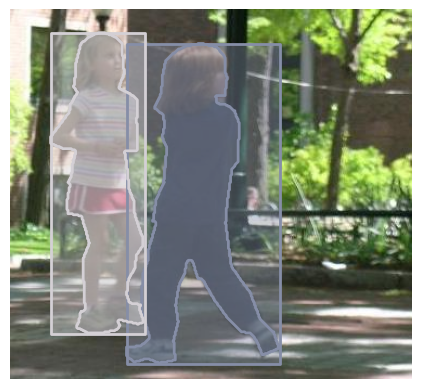

In [13]:
I = io.imread(COCO_ROOT / "train" / img["file_name"])
plt.imshow(I)
plt.axis("off")
catIds = coco.getCatIds(catNms=nms_names)
annIds = coco.getAnnIds(imgIds=img["id"], catIds=catIds, iscrowd=None)
anns = coco.loadAnns(annIds)
coco.showAnns(anns, draw_bbox=True)
plt.show()

In [14]:
# 그림에 그려진 값의 원본. 윤곽선 좌표는 길어서 제외하고 봅니다
[{key: value for key, value in ann.items() if key != "segmentation"} for ann in anns]

[{'id': 1,
  'image_id': 1,
  'category_id': 1,
  'bbox': [107, 31, 142, 296],
  'area': 42032,
  'iscrowd': 0},
 {'id': 2,
  'image_id': 1,
  'category_id': 1,
  'bbox': [37, 21, 87, 278],
  'area': 24186,
  'iscrowd': 0}]

`bbox`가 `[x, y, w, h]`인 것을 확인하세요. 색칠된 영역은 `segmentation` 다각형이고, 박스는 `bbox`입니다. 마스크로부터 직접 계산했으니 사람의 윤곽에 꼭 맞습니다.

**Q. `iscrowd`는 무엇일까요?**

<details><summary>답</summary>

사람이 너무 많이 뭉쳐 있어 한 명씩 구분하기 어려운 영역을 한 덩어리로 라벨링했다는 표시입니다. COCO 평가에서는 `iscrowd=1`인 정답을 일반 객체처럼 세지 않습니다. 여기서는 모두 한 명씩 라벨링되어 있어 0입니다.
</details>

### 실습 2. 이미지당 객체 수 세기

`coco`를 받아 `{이미지 번호: 객체 수}` 딕셔너리를 돌려주는 `count_boxes_per_image`를 작성하고, 평균과 최댓값을 출력하세요. 이 값은 2교시에서 "한 이미지에 박스를 최대 몇 개까지 담을지" 정할 때 필요합니다.

In [15]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def count_boxes_per_image(coco: COCO) -> dict[int, int]:
    """이미지 번호별 어노테이션 수를 셉니다."""
    return {image_id: len(coco.getAnnIds(imgIds=image_id)) for image_id in coco.getImgIds()}


counts = count_boxes_per_image(coco)
assert sum(counts.values()) == len(coco.getAnnIds())
assert len(counts) == len(coco.getImgIds())
print(f"이미지당 평균 {np.mean(list(counts.values())):.2f}개, 최대 {max(counts.values())}개")
```
</details>

---
# 2교시. 나만의 Dataset

## 2.1 내 데이터셋을 PyTorch에 올리기

분류와 달리 탐지 데이터는 두 가지가 까다롭습니다.

1. **이미지를 줄이면 박스 좌표도 같이 바뀌어야 합니다.** 500×400 이미지를 256×256으로 줄이면 박스의 x는 256/500배, y는 256/400배가 되어야 합니다.
2. **이미지마다 박스 개수가 다릅니다.** `DataLoader`의 기본 동작은 샘플들을 같은 크기로 쌓는 것이라, 개수가 다르면 에러가 납니다.

두 번째 문제는 여기서는 **빈칸을 0으로 채워(padding)** 크기를 맞춰 풉니다. 실습 3에서는 다른 방법도 씁니다.

먼저 첫 번째 문제가 실제로 어떻게 보이는지 확인합니다. 이미지만 줄이고 좌표를 그대로 두면 박스가 엉뚱한 곳에 그려집니다.

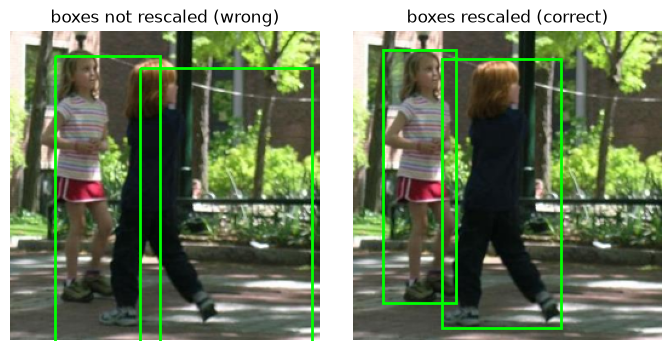

In [16]:
RESIZE_TO = 256

sample_info = coco.loadImgs(1)[0]
sample_image = Image.open(COCO_ROOT / "train" / sample_info["file_name"]).convert("RGB")
sample_boxes = [ann["bbox"] for ann in coco.loadAnns(coco.getAnnIds(imgIds=sample_info["id"]))]
scale_x = RESIZE_TO / sample_info["width"]
scale_y = RESIZE_TO / sample_info["height"]

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, (sx, sy), title in zip(axes, [(1.0, 1.0), (scale_x, scale_y)], ["boxes not rescaled (wrong)", "boxes rescaled (correct)"]):
    ax.imshow(sample_image.resize((RESIZE_TO, RESIZE_TO)))
    for x, y, w, h in sample_boxes:
        ax.add_patch(Rectangle((x * sx, y * sy), w * sx, h * sy, fill=False, color="lime", lw=2))
    ax.set_title(title)
    ax.set_xlim(0, RESIZE_TO)
    ax.set_ylim(RESIZE_TO, 0)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Dataset 정의

`__getitem__`이 하는 일은 네 단계입니다. 이미지 번호를 찾고, 그 이미지의 라벨을 불러오고, 박스 크기를 이미지에 맞추고, 빈칸을 채워 돌려줍니다.

원본 코드에서 고친 곳이 셋 있습니다.

- 이미지만 256×256으로 줄이고 박스는 그대로 두던 것을 **박스도 같은 비율로 바꿉니다**.
- `Normalize`의 `std`가 0.1인데 화면에 그릴 때는 `std=0.5`로 되돌려 색이 깨졌습니다. 둘을 0.5로 맞춥니다.
- 박스가 `max_num_boxes`보다 많으면 에러가 나던 것을 넘치는 부분만 자르도록 합니다.

In [17]:
class MyCocoDataset(Dataset):
    def __init__(self, root: str | Path, size: int = RESIZE_TO) -> None:
        super().__init__()
        self.root = Path(root)
        self.size = size
        # COCO 데이터셋 로드
        self.coco = COCO(str(self.root / "_annotations.coco.json"))

        # 카테고리 정보 추출
        cats = self.coco.loadCats(self.coco.getCatIds())
        names = [cat["name"] for cat in cats]
        self.catIds = self.coco.getCatIds(catNms=names)

        # 어노테이션이 있는 이미지만 선택. 정답이 없는 이미지는 탐지 학습에 쓸 수 없다
        self.imgIds = []
        for idx in self.coco.getImgIds():
            annotations_ids = self.coco.getAnnIds(imgIds=idx, iscrowd=False)
            if len(annotations_ids) != 0:
                self.imgIds.append(idx)

        # 이미지 전처리 파이프라인. 배치로 쌓으려면 이미지 크기가 모두 같아야 한다
        self.preprocess = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
        ])

        # 이미지마다 다른 박스 수를 이 크기로 맞춘다. 실습 2의 최댓값보다 넉넉하게 잡는다
        self.max_num_boxes = 20

    def __getitem__(self, index: int) -> tuple[torch.Tensor, np.ndarray]:   # 인덱스에 접근할 때 호출
        imageId = self.imgIds[index]
        imageInfo = self.coco.loadImgs(imageId)[0]

        annIds = self.coco.getAnnIds(imgIds=imageId, catIds=self.catIds)
        anns = self.coco.loadAnns(annIds)
        bboxes = np.array([ann["bbox"] for ann in anns], dtype=np.float32).reshape(-1, 4)

        # 이미지를 줄이는 비율만큼 박스의 x, 너비와 y, 높이를 각각 바꾼다
        bboxes[:, [0, 2]] *= self.size / imageInfo["width"]
        bboxes[:, [1, 3]] *= self.size / imageInfo["height"]

        # 모든 샘플이 (max_num_boxes, 4)가 되도록 남는 칸은 0으로 둔다
        padded_bboxes = np.zeros((self.max_num_boxes, 4), dtype=np.float32)
        num_boxes = min(len(bboxes), self.max_num_boxes)
        padded_bboxes[:num_boxes] = bboxes[:num_boxes]

        with open(self.root / imageInfo["file_name"], "rb") as f:
            img = Image.open(f).convert("RGB")
        return self.preprocess(img), padded_bboxes

    def __len__(self) -> int:
        return len(self.imgIds)

### Dataloader 정의

Colab은 `num_workers=2`로 데이터를 병렬로 읽어 빠르게 할 수 있습니다.

In [18]:
batch_size = 4

cocotrainset = MyCocoDataset(COCO_ROOT / "train")
cocotrainloader = DataLoader(cocotrainset, batch_size=batch_size, shuffle=True, num_workers=2)
print("샘플 수:", len(cocotrainset), "/ 배치 수:", len(cocotrainloader))

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
샘플 수: 136 / 배치 수: 34


배치 하나를 꺼내 그림으로 확인합니다. 숫자만 보는 대신 **박스를 이미지 위에 그려 보는 것**이 탐지 데이터 검증의 기본입니다. 이미지와 박스가 어긋나면 모델이 아무리 좋아도 학습이 안 됩니다.

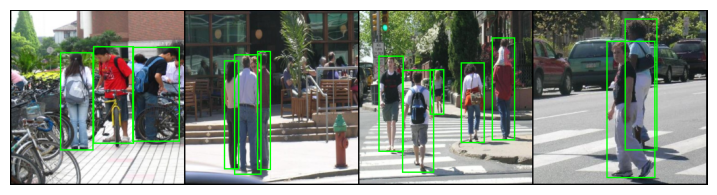

images: torch.Size([4, 3, 256, 256]) / bboxes: torch.Size([4, 20, 4])
sample 0:
tensor([[ 72.1611,  61.0000,  49.8255, 145.0000],
        [121.9866,  52.5000,  59.5615, 143.5000],
        [179.8300,  53.0000,  69.2975, 140.5000]])
sample 1:
tensor([[ 72.0777,  64.0000,  40.1812, 178.5905],
        [ 57.5793,  73.7524,  22.3689, 160.3048],
        [106.0453,  59.1238,  20.7120, 176.1524]])


In [19]:
def imshow(img: torch.Tensor) -> None:
    """정규화된 이미지를 원래 밝기로 되돌려 보여 줍니다."""
    img = img / 2 + 0.5     # unnormalize: mean=0.5, std=0.5의 역변환
    npimg = img.numpy()
    plt.figure(figsize=(9, 3))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()


def draw_batch(images: torch.Tensor, bboxes: torch.Tensor) -> torch.Tensor:
    """배치의 이미지마다 박스를 그려 하나의 격자 이미지로 만듭니다."""
    drawn = []
    for image, boxes in zip(images, bboxes):
        boxes = boxes[boxes[:, 2] > 0]   # 너비가 0인 칸은 채워 넣은 빈칸이다
        xyxy = torch.cat([boxes[:, :2], boxes[:, :2] + boxes[:, 2:]], dim=1)
        uint8_image = ((image / 2 + 0.5) * 255).clamp(0, 255).to(torch.uint8)
        drawn.append(draw_bounding_boxes(uint8_image, xyxy, colors="lime", width=2))
    return (make_grid(drawn).float() / 255 - 0.5) * 2   # imshow가 되돌리는 범위에 맞춘다


# 학습용 이미지를 무작위로 가져오기
dataiter = iter(cocotrainloader)
images, bboxes = next(dataiter)

# 이미지 보여주기
imshow(draw_batch(images, bboxes))
# 정답 출력. 빈칸(0)은 빼고 처음 두 샘플만 본다
print("images:", images.shape, "/ bboxes:", bboxes.shape)
for j in range(2):
    print(f"sample {j}:\n{bboxes[j][bboxes[j][:, 2] > 0]}")

이제 본인 데이터를 가지고 모델을 학습시킬 수 있습니다! 다만 0으로 채운 칸은 학습할 때 다시 걸러 내야 하니 번거롭습니다. 그래서 실제 탐지 코드는 보통 `collate_fn`으로 박스를 **리스트에 담아** 넘깁니다. torchvision의 탐지 모델도 이 방식을 씁니다.

### 실습 3. 박스 수가 달라도 되는 DataLoader

`collate_fn`은 샘플 목록을 받아 배치를 만드는 함수입니다. 다음을 만족하는 `detection_collate`를 작성하고 `DataLoader`에 넘겨 보세요.

- 이미지는 `(배치, 3, 256, 256)` 텐서로 쌓습니다.
- 박스는 패딩을 뺀 `(N, 4)` 텐서들의 리스트로 돌려줍니다.

In [20]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def detection_collate(batch: list[tuple[torch.Tensor, np.ndarray]]) -> tuple[torch.Tensor, list[torch.Tensor]]:
    """이미지는 쌓고, 박스는 개수가 달라 리스트로 둡니다."""
    images = torch.stack([image for image, _ in batch])
    targets = [torch.as_tensor(boxes[boxes[:, 2] > 0]) for _, boxes in batch]
    return images, targets


loader = DataLoader(cocotrainset, batch_size=4, collate_fn=detection_collate)
images, targets = next(iter(loader))
assert images.shape == (4, 3, RESIZE_TO, RESIZE_TO)
assert all(t.ndim == 2 and t.shape[1] == 4 and len(t) > 0 for t in targets)
assert all((t[:, 0] + t[:, 2] <= RESIZE_TO + 1).all() for t in targets)   # 박스가 이미지 안에 있는가
print("박스 수:", [len(t) for t in targets])
```
</details>

---
# 3교시. R-CNN 계열

## 3.1 2013년부터 발전해 온 알고리즘, R-CNN

오늘날 실시간 탐지에서 가장 널리 쓰이는 계열 중 하나는 YOLO입니다. 그 전에 R-CNN 시리즈를 공부합니다. YOLO가 어떤 문제를 풀려고 나왔는지 이해하는 데 꼭 필요하고, 앵커(anchor) 같은 핵심 아이디어가 여기서 나왔습니다. 정확도가 중요한 곳에서는 Faster R-CNN 계열이 지금도 쓰입니다.

1. [R-CNN](https://arxiv.org/abs/1311.2524)
2. [Fast R-CNN](https://arxiv.org/abs/1504.08083)
3. [Faster R-CNN](https://arxiv.org/abs/1506.01497)

### 기본 구조

R-CNN(Region-based Convolutional Neural Network) 시리즈는 네 단계로 이루어집니다.

- **Region Proposal**: 전체 이미지에서 객체가 있을 법한 영역을 추천합니다.
- **Feature Extraction**: 추천받은 영역의 특징을 뽑습니다.
- **Classifier**: 어떤 객체인지 구분하고 박스 위치를 다듬습니다.
- **Non-Maximum Suppression**: 같은 객체에 겹친 박스 중 점수가 가장 높은 것만 남깁니다.

"먼저 후보를 고르고(1단계) 그 다음 분류한다(2단계)"는 구조라서 **2-stage 탐지기**라고 부릅니다. 세 모델의 차이는 "어느 단계가 신경망 바깥에 있느냐"로 보면 가장 잘 보입니다. 아래 그림을 위에서 아래로 읽으면서 회색(따로 학습하거나 학습하지 않는 부분)이 어떻게 사라지는지 보세요. 맨 왼쪽의 입력 이미지는 셋 다 회색이고, 맨 아래 Faster R-CNN에서는 그것만 남습니다.

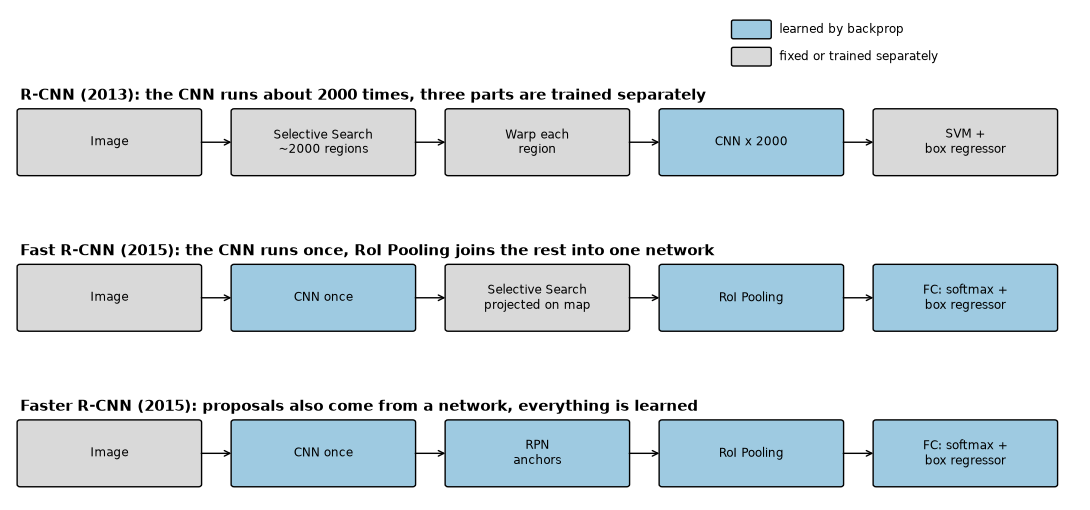

In [21]:
def draw_flow(ax: plt.Axes, y: float, title: str, steps: list[tuple[str, bool]]) -> None:
    """(글자, 학습되는 신경망 여부) 목록을 왼쪽에서 오른쪽으로 잇는 흐름도를 그립니다."""
    box_width, gap = 1.75, 0.35
    ax.text(0, y + 0.5, title, fontsize=11, fontweight="bold", va="bottom")
    for i, (text, learned) in enumerate(steps):
        x = i * (box_width + gap)
        color = "#9ecae1" if learned else "#d9d9d9"
        ax.add_patch(FancyBboxPatch((x, y - 0.4), box_width, 0.8, boxstyle="round,pad=0.03", fc=color, ec="black"))
        ax.text(x + box_width / 2, y, text, ha="center", va="center", fontsize=8.5)
        if i < len(steps) - 1:
            ax.annotate("", xy=(x + box_width + gap, y), xytext=(x + box_width, y), arrowprops={"arrowstyle": "->"})


fig, ax = plt.subplots(figsize=(11, 5.2))
draw_flow(ax, 4.4, "R-CNN (2013): the CNN runs about 2000 times, three parts are trained separately", [
    ("Image", False), ("Selective Search\n~2000 regions", False), ("Warp each\nregion", False),
    ("CNN x 2000", True), ("SVM +\nbox regressor", False)])
draw_flow(ax, 2.4, "Fast R-CNN (2015): the CNN runs once, RoI Pooling joins the rest into one network", [
    ("Image", False), ("CNN once", True), ("Selective Search\nprojected on map", False),
    ("RoI Pooling", True), ("FC: softmax +\nbox regressor", True)])
draw_flow(ax, 0.4, "Faster R-CNN (2015): proposals also come from a network, everything is learned", [
    ("Image", False), ("CNN once", True), ("RPN\nanchors", True),
    ("RoI Pooling", True), ("FC: softmax +\nbox regressor", True)])
ax.add_patch(FancyBboxPatch((7.0, 5.75), 0.35, 0.2, boxstyle="round,pad=0.02", fc="#9ecae1", ec="black"))
ax.text(7.45, 5.85, "learned by backprop", fontsize=8.5, va="center")
ax.add_patch(FancyBboxPatch((7.0, 5.4), 0.35, 0.2, boxstyle="round,pad=0.02", fc="#d9d9d9", ec="black"))
ax.text(7.45, 5.5, "fixed or trained separately", fontsize=8.5, va="center")
ax.set_xlim(-0.1, 10.4)
ax.set_ylim(-0.2, 6.1)
ax.axis("off")
plt.tight_layout()
plt.show()

## 3.2 R-CNN

- R-CNN 시리즈의 선구자입니다. 전통적인 이미지 처리 방식과 딥러닝 기반 방식을 섞은 구조입니다.
- **Selective Search** 알고리즘(픽셀 유사도로 영역을 묶어 나가는 방법)으로 약 2000개의 영역을 추천합니다.
- 각 영역을 같은 크기로 늘려 CNN에 넣고 특징을 뽑습니다.
- SVM(Support Vector Machine)으로 객체를 구분합니다. 박스 위치는 별도의 회귀 모델로 다듬습니다.

**문제점**

- SVM, CNN, Selective Search가 나뉘어 있어 **한 번에 학습되지 않습니다**.
- 추천 영역 약 2000개를 각각 CNN에 넣으므로 **연산 시간이 오래 걸립니다**.

그림과 설명 출처: [구조 그림](https://wikidocs.net/images/page/136494/rcnn_3.png) · [위키독스 설명](https://wikidocs.net/148633)

## 3.3 Fast R-CNN

R-CNN의 두 문제, 즉 2000번의 CNN 동작과 한 번에 학습할 수 없는 문제를 해결했습니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FIiNzk%2FbtqA8iSURGO%2F8F29HIsdwxAd6kMUnuKuu1%2Fimg.png))

### RoI Pooling

2000번의 CNN을 없애기 위해 RoI Pooling을 넣었습니다.

- 입력 이미지를 CNN에 **한 번만** 통과시켜 feature map을 만듭니다. feature map 크기는 입력 크기에 따라 달라집니다.
- Selective Search의 결과(원본 이미지 좌표)를 feature map 좌표로 옮깁니다(Projection).
- 옮긴 영역을 미리 정한 격자(논문의 VGG16에서는 **7×7**)로 나눕니다.
- 칸마다 max pooling을 해서, 영역의 크기와 상관없이 **항상 7×7 크기의 특징**을 얻습니다. 이것을 펼쳐 FC layer에 넣습니다.

원본 자료에는 "feature map이 7×7"이라고 되어 있었는데, 7×7로 고정되는 것은 feature map이 아니라 **RoI Pooling의 출력**입니다. FC layer는 입력 크기가 고정되어야 하므로 이 단계가 꼭 필요합니다. 코드로 확인해 봅니다.

In [22]:
# 800x800 이미지를 VGG16에 넣으면 나올 feature map 크기를 흉내 낸다(stride 16이므로 50x50)
feature_map = torch.randn(1, 512, 50, 50)
# 크기가 전혀 다른 영역 두 개. 좌표는 원본 이미지 기준이다
regions = [torch.tensor([[0.0, 0.0, 160.0, 320.0], [100.0, 100.0, 740.0, 500.0]])]
pooled = roi_pool(feature_map, regions, output_size=(7, 7), spatial_scale=1 / 16)
print("입력 feature map:", feature_map.shape)
print("RoI Pooling 출력:", pooled.shape, "<- 영역 2개가 모두 512 x 7 x 7")

입력 feature map: torch.Size([1, 512, 50, 50])
RoI Pooling 출력: torch.Size([2, 512, 7, 7]) <- 영역 2개가 모두 512 x 7 x 7


### End-to-End Network

RoI Pooling 덕분에 따로 동작하던 분류기와 박스 회귀가 하나의 네트워크로 합쳐졌습니다. 시작부터 끝까지 한 번에 연결된 **End-to-End Network**입니다(Selective Search 단계는 빼고요).

### 단점

- 처음에 동작하는 Selective Search는 네트워크가 아닙니다.
- 네트워크 밖에서 CPU로 도는 이 부분이 속도의 병목(bottleneck)입니다.

속도 비교 표 출처: [비교 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FoHUnL%2FbtqBc5dG1ix%2F9EWJiCVhnHoTFZQTtCckYK%2Fimg.png) · [블로그 설명](https://ganghee-lee.tistory.com/36)

## 3.4 Faster R-CNN

이름에서 알 수 있듯 조금 '더' 빠른 탐지 알고리즘입니다.

- Fast R-CNN의 병목이었던 Selective Search를 신경망으로 바꿨습니다.
- 모든 단계를 네트워크로 진행하므로 **한 번에 학습할 수 있습니다**.
- 이전 방식들에 비해 속도를 크게 개선했습니다.

전체 구조 그림 출처: [Faster R-CNN 구조](https://miro.medium.com/v2/resize:fit:4800/format:webp/1*tTqg3W165itg-LVRFxHJfA.jpeg)

### Region Proposal Network (RPN)

이전 방식들은 모두 Selective Search로 객체의 예상 위치를 뽑았습니다. RPN은 Faster R-CNN이 제안한 방식으로, 이 일을 합성곱 층으로 합니다.

쉬운 숫자로 보겠습니다. 800×800 이미지에서 8×8×512 feature map을 뽑았다면, feature map의 한 칸은 원본의 100×100 영역을 대표합니다. (실제 VGG16은 stride가 16이라 50×50이 나옵니다. 3.8절 코드에서 확인합니다.)

1. feature map에 3×3 합성곱을 적용합니다(패딩으로 크기 유지).
2. 각 칸마다 크기와 비율이 정해진 **앵커(anchor) 박스 9개**를 미리 깔아 둡니다.
3. 1×1 합성곱으로 앵커마다 **객체인지 아닌지** 점수를 냅니다. 논문은 2×9=18채널(8×8×18)입니다.
4. 또 다른 1×1 합성곱으로 앵커마다 **박스 보정값 4개**(중심 x, y, 너비, 높이)를 냅니다. 4×9=36채널(8×8×36)입니다.
5. 객체 점수가 큰 순서로 추려 다음 단계로 넘깁니다.

박스를 맨땅에서 맞히는 대신, **이미 깔아 둔 앵커를 조금 고치는 문제**로 바꾼 것이 핵심 아이디어입니다.

RPN 그림 출처: [RPN 구조](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fo7PTm%2FbtqAXir1rPy%2FVbzsfY9JMY9N3ixCe3zxb0%2Fimg.png)

아래는 논문과 같은 크기 3종(128, 256, 512), 비율 3종(0.5, 1, 2)으로 만든 앵커 9개입니다. torchvision의 함수로 직접 계산했습니다.

앵커 수: 9
너비: [182.0, 362.0, 724.0, 128.0, 256.0, 512.0, 90.0, 182.0, 362.0]
높이: [90.0, 182.0, 362.0, 128.0, 256.0, 512.0, 182.0, 362.0, 724.0]


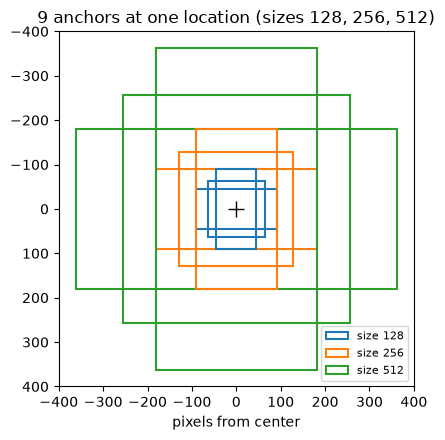

In [23]:
anchor_generator_demo = torchvision.models.detection.rpn.AnchorGenerator(sizes=((128, 256, 512),), aspect_ratios=((0.5, 1.0, 2.0),))
base_anchors = anchor_generator_demo.generate_anchors((128, 256, 512), (0.5, 1.0, 2.0))
widths = base_anchors[:, 2] - base_anchors[:, 0]
heights = base_anchors[:, 3] - base_anchors[:, 1]
print("앵커 수:", len(base_anchors))
print("너비:", widths.tolist())
print("높이:", heights.tolist())

fig, ax = plt.subplots(figsize=(4.5, 4.5))
colors = ["tab:blue", "tab:orange", "tab:green"]
size_names = [128, 256, 512]
for i, (x1, y1, x2, y2) in enumerate(base_anchors.tolist()):
    # generate_anchors는 비율별로 크기 3개씩 묶어 돌려주므로 i % 3이 크기 순번이다
    label = f"size {size_names[i]}" if i < 3 else None
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=colors[i % 3], lw=1.5, label=label))
ax.legend(loc="lower right", fontsize=8)
ax.plot(0, 0, "k+", markersize=12)
ax.set_xlim(-400, 400)
ax.set_ylim(400, -400)
ax.set_aspect("equal")
ax.set_title("9 anchors at one location (sizes 128, 256, 512)")
ax.set_xlabel("pixels from center")
plt.tight_layout()
plt.show()

### 단점

RPN으로 박스를 먼저 구하고 그 다음 분류기로 객체를 구분하는 2단계 구성이라 속도에 한계가 있습니다.

→ 박스 출력과 분류를 **동시에** 하자. 이것이 4교시의 YOLO입니다.

## 3.5 NMS: 겹친 박스 정리

탐지기는 같은 사람 근처에 비슷한 박스를 여러 개 냅니다. **NMS(Non-Maximum Suppression)** 는 다음을 반복해 하나만 남깁니다.

1. 점수가 가장 높은 박스를 고릅니다.
2. 그 박스와 IoU가 기준값보다 큰 박스를 모두 버립니다.
3. 남은 박스로 1번을 반복합니다.

In [24]:
boxes_demo = torch.tensor([
    [10.0, 10.0, 60.0, 60.0],
    [12.0, 12.0, 62.0, 62.0],     # 첫 박스와 거의 같은 위치
    [14.0, 8.0, 64.0, 58.0],      # 첫 박스와 거의 같은 위치
    [100.0, 100.0, 150.0, 150.0], # 멀리 있는 다른 객체
])
scores_demo = torch.tensor([0.9, 0.8, 0.7, 0.6])
print("남은 박스 번호:", nms(boxes_demo, scores_demo, iou_threshold=0.5).tolist())

남은 박스 번호: [0, 3]


### 실습 4. NMS 직접 구현

`my_nms`를 작성하세요. 입력은 `(N, 4)` 박스, `(N,)` 점수, 기준값이고 출력은 남길 박스의 번호(점수 높은 순)입니다. `box_iou`와 `argsort`를 쓰면 짧게 쓸 수 있습니다.

In [25]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def my_nms(boxes: torch.Tensor, scores: torch.Tensor, iou_threshold: float) -> torch.Tensor:
    """점수 순으로 박스를 고르며 많이 겹치는 박스를 버립니다."""
    order = scores.argsort(descending=True)
    keep = []
    while len(order) > 0:
        best = order[0]
        keep.append(best.item())
        rest = order[1:]
        ious = box_iou(boxes[best].unsqueeze(0), boxes[rest]).squeeze(0)
        # 기준값 이하로 겹치는 박스만 다음 차례로 넘긴다
        order = rest[ious <= iou_threshold]
    return torch.tensor(keep, dtype=torch.int64)


assert my_nms(boxes_demo, scores_demo, 0.5).tolist() == [0, 3]
# 무작위 박스 300개로 torchvision과 결과가 같은지 비교
torch.manual_seed(0)
top_left = torch.rand(300, 2) * 200
random_boxes = torch.cat([top_left, top_left + 20 + torch.rand(300, 2) * 60], dim=1)
random_scores = torch.rand(300)
assert my_nms(random_boxes, random_scores, 0.5).tolist() == nms(random_boxes, random_scores, 0.5).tolist()
print("남은 박스 수:", len(my_nms(random_boxes, random_scores, 0.5)), "/ 300")
```
</details>

## 3.6 Faster R-CNN 코드 살펴보기

[jwyang/faster-rcnn.pytorch의 lib/model 폴더](https://github.com/jwyang/faster-rcnn.pytorch/tree/master/lib/model)에는 Faster R-CNN의 코드가 부분별로 나뉘어 있습니다. 폴더 구성만 봐도 지금까지 배운 부품이 그대로 보입니다.

| 폴더 | 내용 |
|---|---|
| `faster_rcnn/` | 전체 모델 |
| `rpn/` | Region Proposal Network |
| `roi_pooling/`, `roi_align/`, `roi_crop/` | 영역을 고정 크기로 만드는 방법들 |
| `nms/` | 겹친 박스 제거 |
| `utils/` | 공통 도구 |

코드가 깔끔하게 정리되어 있어 읽기 좋습니다. 다만 Colab용 파일이 아니라 `.py`를 돌려야 하므로 별도의 환경 설정이 필요하고, 오래된 PyTorch를 기준으로 작성되어 있습니다.

다행히 torchvision에 Faster R-CNN의 부품과 조립 함수가 있습니다. 이번에는 그것을 써서 **VGG16 기반 Faster R-CNN을 부품부터 조립**하고 학습해 봅니다.

## 3.7 패키지와 데이터 준비

필요한 패키지는 강의 맨 앞에서 모두 불러왔습니다. 원본에서 쓰던 `imgaug`는 지금은 동작하지 않아서 박스 변환까지 지원하는 `albumentations`로 바꿨습니다.

원본은 Pascal VOC 2012 전체(이미지 17,125장, 약 2GB)를 Google Drive에서 복사해 썼습니다. 입문 실습에 쓰기에는 무거우므로, 여기서는 Penn-Fudan을 **VOC와 똑같은 폴더 구조와 XML 형식으로 변환**해 씁니다. 그러면 아래 코드는 전체 VOC에서도 경로와 개수만 바꾸면 그대로 돕니다.

```text
VOCdevkit/VOC2012/
├── Annotations/   이미지별 XML 라벨
└── JPEGImages/    이미지
```

> **전체 VOC로 해 보려면** [VOC 2012 공식 페이지](http://host.robots.ox.ac.uk/pascal/VOC/voc2012/)에서 `VOCtrainval_11-May-2012.tar`를 받아 압축을 풀고, 다음처럼 바꾸세요. 이 노트북을 검증할 때 전체 VOC로는 실행하지 않았습니다. T4 GPU에서도 여러 시간이 걸리는 규모입니다.
>
> 1. 다음 셀(Penn-Fudan 변환)은 건너뛰고, `VOC_ROOT = Path("VOCdevkit/VOC2012")`만 실행합니다.
> 2. 라벨 집합 셀의 `xml_list`를 `sorted(os.listdir(VOC_ROOT / "Annotations"))`로 바꿉니다. 이름순이므로 섞어서 쓰는 편이 좋습니다.
> 3. 학습 셀의 `len_data`를 원본 설정인 `15000`으로, `term`을 `1000`으로 바꿉니다.
> 4. 3.10절의 평가는 Penn-Fudan 전용이므로 건너뜁니다.

In [26]:
VOC_ROOT = DATA_ROOT / "VOCdevkit_penn" / "VOC2012"


def write_voc_xml(sample: dict, xml_path: Path) -> None:
    """VOC 형식 XML 라벨 하나를 씁니다."""
    root = Element("annotation")
    SubElement(root, "filename").text = sample["path"].name
    size = SubElement(root, "size")
    SubElement(size, "width").text = str(sample["width"])
    SubElement(size, "height").text = str(sample["height"])
    SubElement(size, "depth").text = "3"
    for obj in sample["objects"]:
        node = SubElement(root, "object")
        SubElement(node, "name").text = "person"
        bndbox = SubElement(node, "bndbox")
        for tag, value in zip(["xmin", "ymin", "xmax", "ymax"], obj["box"]):
            SubElement(bndbox, tag).text = str(value)
    ElementTree(root).write(xml_path)


(VOC_ROOT / "Annotations").mkdir(parents=True, exist_ok=True)
(VOC_ROOT / "JPEGImages").mkdir(parents=True, exist_ok=True)
for sample in samples:
    shutil.copy(sample["path"], VOC_ROOT / "JPEGImages" / sample["path"].name)
    write_voc_xml(sample, VOC_ROOT / "Annotations" / f"{sample['path'].stem}.xml")

print((VOC_ROOT / "Annotations" / f"{samples[0]['path'].stem}.xml").read_text()[:330])

<annotation><filename>FudanPed00001.png</filename><size><width>559</width><height>536</height><depth>3</depth></size><object><name>person</name><bndbox><xmin>159</xmin><ymin>181</ymin><xmax>302</xmax><ymax>431</ymax></bndbox></object><object><name>person</name><bndbox><xmin>419</xmin><ymin>170</ymin><xmax>535</xmax><ymax>486</ym


### 데이터셋 라벨 로드 및 읽기

위와 같은 XML에서 파일 이름, 물체 이름, 박스를 꺼내는 함수입니다.

In [27]:
def xml_parser(xml_path: str | Path) -> tuple[str, list[str], list[list[int]]]:
    """VOC XML 파일에서 파일 이름, 물체 이름 목록, xyxy 박스 목록을 읽습니다."""
    tree = Et.parse(xml_path)   # 파일 객체를 직접 열면 닫는 일을 잊기 쉬워 경로를 넘긴다
    root = tree.getroot()
    file_name = root.find("filename").text
    object_name = []
    bbox = []
    objects = root.findall("object")
    for _object in objects:
        name = _object.find("name").text
        object_name.append(name)
        bndbox = _object.find("bndbox")
        one_bbox = []
        xmin = bndbox.find("xmin").text
        one_bbox.append(int(float(xmin)))
        ymin = bndbox.find("ymin").text
        one_bbox.append(int(float(ymin)))
        xmax = bndbox.find("xmax").text
        one_bbox.append(int(float(xmax)))
        ymax = bndbox.find("ymax").text
        one_bbox.append(int(float(ymax)))
        bbox.append(one_bbox)
    return file_name, object_name, bbox

### 이미지에 박스 그리기

In [28]:
def makeBox(voc_im: np.ndarray, bbox: list[list[float]], objects: list[str]) -> np.ndarray:
    """이미지 복사본에 초록색 박스와 이름을 그립니다."""
    image = voc_im.copy()
    for i in range(len(objects)):
        cv2.rectangle(image, (int(bbox[i][0]), int(bbox[i][1])), (int(bbox[i][2]), int(bbox[i][3])), color=(0, 255, 0), thickness=2)
        cv2.putText(image, objects[i], (int(bbox[i][0]), int(bbox[i][1]) - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)   # 크기, 색, 굵기
    return image

### 라벨 집합 만들기

물체 이름을 번호로 바꾸는 사전을 만듭니다. 번호를 **1부터** 주는 데 이유가 있습니다. torchvision의 탐지 모델은 0번을 **배경**으로 약속하기 때문입니다.

학습과 검증은 1교시의 COCO 분할과 같게 맞춥니다. `xml_list`의 앞쪽 `len_data`개를 학습에 쓰므로 학습 파일을 앞에 둡니다. 원본처럼 이름순으로 정렬한 채 앞에서 자르면, 이 데이터에서는 Fudan 이미지가 모두 학습에, Penn 이미지가 모두 검증에 몰립니다.

In [29]:
train_stems = sorted(s["path"].stem for s in train_samples)
valid_stems = sorted(s["path"].stem for s in valid_samples)
xml_list = [f"{stem}.xml" for stem in train_stems + valid_stems]

label_set = set()

for i in range(len(xml_list)):
    xml_path = VOC_ROOT / "Annotations" / xml_list[i]
    file_name, object_name, bbox = xml_parser(xml_path)
    for name in object_name:
        label_set.add(name)

label_set = sorted(list(label_set))

label_dic = {}
for i, key in enumerate(label_set):
    label_dic[key] = (i + 1)

print(label_dic)

{'person': 1}


### 데이터셋 정의

원본과 달라진 점은 다음과 같습니다.

- `imgaug`를 `albumentations`로 바꿨습니다. 뒤집기(`HorizontalFlip`)와 짧은 변을 600으로 맞추기(`SmallestMaxSize`)는 그대로이고, **박스도 함께 변환됩니다**.
- 생성자로 받은 `self.xml_list`를 쓰지 않고 바깥 전역 변수 `xml_list`를 읽던 오류를 고쳤습니다.

`targets`를 리스트로 한 번 더 감싸고 뒤의 학습 코드에서 `squeeze_`를 하는 것은 배치 크기 1로 기본 `DataLoader`를 그대로 쓰기 위한 방법입니다. 이미지 크기가 제각각이어서 배치 크기를 키우려면 실습 3처럼 `collate_fn`이 필요합니다.

In [30]:
class Pascal_Voc(Dataset):
    def __init__(self, xml_list: list[str], len_data: int) -> None:
        self.xml_list = xml_list
        self.len_data = len_data
        self.to_tensor = transforms.ToTensor()
        self.transform = A.Compose(
            [A.HorizontalFlip(p=0.5), A.SmallestMaxSize(max_size=600)],
            bbox_params=A.BboxParams(format="pascal_voc", label_fields=["object_names"]),
        )

    def __len__(self) -> int:
        return self.len_data

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, list[dict[str, torch.Tensor]]]:
        xml_path = VOC_ROOT / "Annotations" / self.xml_list[idx]

        file_name, object_name, bbox = xml_parser(xml_path)
        image_path = VOC_ROOT / "JPEGImages" / file_name
        image = Image.open(image_path).convert("RGB")
        image = np.array(image)

        transformed = self.transform(image=image, bboxes=bbox, object_names=object_name)
        image = self.to_tensor(transformed["image"])

        targets = []
        d = {}
        d["boxes"] = torch.tensor(np.array(transformed["bboxes"]), dtype=torch.float32, device=device)
        d["labels"] = torch.tensor([label_dic[x] for x in transformed["object_names"]], dtype=torch.int64, device=device)
        targets.append(d)

        return image, targets

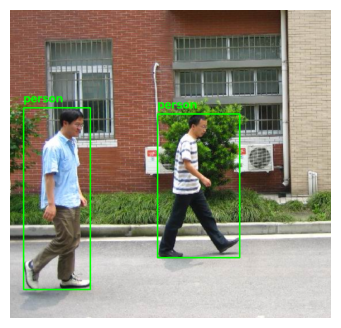

이미지 크기: torch.Size([3, 600, 626])


In [31]:
# 변환 후에도 박스가 사람과 맞는지 눈으로 확인한다
check_dataset = Pascal_Voc(xml_list, len(train_stems))
check_image, check_targets = check_dataset[0]
check_np = (check_image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
check_boxes = check_targets[0]["boxes"].cpu().tolist()
plt.figure(figsize=(5, 4))
plt.imshow(makeBox(check_np, check_boxes, ["person"] * len(check_boxes)))
plt.axis("off")
plt.show()
print("이미지 크기:", check_image.shape)

## 3.8 모델 정의

Faster R-CNN을 부품별로 만들어 조립합니다.

| 부품 | 코드 | 역할 |
|---|---|---|
| Backbone | `vgg16(...).features[:-1]` | 이미지에서 feature map 추출. 마지막 max pooling을 빼서 stride를 16으로 둡니다 |
| Anchor | `AnchorGenerator` | 크기 3종 × 비율 3종 = 위치마다 앵커 9개 |
| RoI Pooling | `MultiScaleRoIAlign` | 영역을 7×7로. 논문의 RoI Pooling을 개선한 RoI Align입니다 |
| Box head | `TwoMLPHead` | 7×7×512를 펼쳐 FC 2층으로 4096차원 특징 생성 |
| Predictor | `FastRCNNPredictor` | 클래스 점수와 클래스별 박스 보정값 출력 |

`num_classes`는 **배경을 포함한 수**입니다. VOC는 20개 클래스 + 배경이라 원본은 21이었고, 여기서는 사람 + 배경으로 2입니다. `box_predictor`를 직접 주었으므로 `num_classes=None`으로 둡니다.

In [32]:
backbone = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).features[:-1]
backbone_out = 512
backbone.out_channels = backbone_out

anchor_generator = torchvision.models.detection.rpn.AnchorGenerator(sizes=((128, 256, 512),), aspect_ratios=((0.5, 1.0, 2.0),))

resolution = 7
roi_pooler = torchvision.ops.MultiScaleRoIAlign(featmap_names=["0"], output_size=resolution, sampling_ratio=2)

num_classes = len(label_dic) + 1   # 배경 포함. 전체 VOC라면 21
box_head = torchvision.models.detection.faster_rcnn.TwoMLPHead(in_channels=backbone_out * (resolution ** 2), representation_size=4096)
box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(4096, num_classes)

model = torchvision.models.detection.FasterRCNN(backbone, num_classes=None,
                   min_size=600, max_size=1000,
                   rpn_anchor_generator=anchor_generator,
                   rpn_pre_nms_top_n_train=6000, rpn_pre_nms_top_n_test=6000,
                   rpn_post_nms_top_n_train=2000, rpn_post_nms_top_n_test=300,
                   rpn_nms_thresh=0.7, rpn_fg_iou_thresh=0.7, rpn_bg_iou_thresh=0.3,
                   rpn_batch_size_per_image=256, rpn_positive_fraction=0.5,
                   box_roi_pool=roi_pooler, box_head=box_head, box_predictor=box_predictor,
                   box_score_thresh=0.05, box_nms_thresh=0.7, box_detections_per_img=300,
                   box_fg_iou_thresh=0.5, box_bg_iou_thresh=0.5,
                   box_batch_size_per_image=128, box_positive_fraction=0.25
                 )
# roi head를 직접 줬으면 num_classes=None으로 함

# 새로 만든 부분(RPN, RoI head)만 논문처럼 작은 값으로 초기화한다. backbone은 사전학습 가중치를 유지한다
for param in model.rpn.parameters():
    torch.nn.init.normal_(param, mean=0.0, std=0.01)

for name, param in model.roi_heads.named_parameters():
    if "bbox_pred" in name:
        torch.nn.init.normal_(param, mean=0.0, std=0.001)
    elif "weight" in name:
        torch.nn.init.normal_(param, mean=0.0, std=0.01)
    if "bias" in name:
        torch.nn.init.zeros_(param)

앞에서 설명한 숫자를 실제 모델로 확인합니다. 800×800 입력의 feature map 크기와 RPN 출력 채널 수입니다.

논문은 앵커마다 객체/비객체 점수 2개(2×9=18채널)를 내지만, torchvision은 **점수 하나에 sigmoid**를 씁니다(1×9=9채널). 표현력은 같고 구현만 다릅니다.

In [33]:
with torch.no_grad():
    demo_feature = model.backbone(torch.zeros(1, 3, 800, 800))
print("feature map:", demo_feature.shape)
print("RPN 점수 층:", model.rpn.head.cls_logits)
print("RPN 박스 층:", model.rpn.head.bbox_pred)
print("이미지 한 장의 앵커 수:", demo_feature.shape[2] * demo_feature.shape[3] * 9)
print(f"전체 파라미터: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

feature map: torch.Size([1, 512, 50, 50])
RPN 점수 층: Conv2d(512, 9, kernel_size=(1, 1), stride=(1, 1))
RPN 박스 층: Conv2d(512, 36, kernel_size=(1, 1), stride=(1, 1))
이미지 한 장의 앵커 수: 22500
전체 파라미터: 136.7M


## 3.9 Training

텐서보드에 학습 과정을 기록합니다. Colab에서는 아래 셀이 텐서보드 화면을 띄웁니다. 원본의 Drive 경로는 현재 폴더로 바꿨습니다.

In [34]:
writer = SummaryWriter("runs/Faster_RCNN")
%load_ext tensorboard
%tensorboard --logdir=runs

텐서보드 화면은 Colab에서 확인


### 손실 정의

Faster R-CNN은 **손실 4개**를 돌려줍니다.

| 이름 | 부분 | 뜻 |
|---|---|---|
| `loss_objectness` | RPN | 앵커가 객체인지 아닌지 |
| `loss_rpn_box_reg` | RPN | 앵커를 얼마나 고쳐야 하는지 |
| `loss_classifier` | RoI head | 영역이 어떤 클래스인지 |
| `loss_box_reg` | RoI head | 영역의 박스를 얼마나 고쳐야 하는지 |

원본은 `loss_rpn_box_reg`에 10을 곱합니다. 이것은 논문의 λ=10에서 온 값입니다. 다만 논문은 박스 손실을 앵커 위치 수(약 2400)로 나눠 두 항이 비슷해지게 한 반면, torchvision은 샘플링한 앵커 수(256개)로 나눕니다. 따라서 여기서 10을 곱하면 논문보다 RPN 박스 손실의 비중이 더 커집니다. 원본 설정대로 두었으니, 숙제에서 1로 바꿔 비교해 보세요.

In [35]:
def Total_Loss(loss: dict[str, torch.Tensor]) -> torch.Tensor:
    """RPN 손실과 Fast R-CNN 손실을 합칩니다."""
    loss_objectness = loss["loss_objectness"]
    loss_rpn_box_reg = loss["loss_rpn_box_reg"]
    loss_classifier = loss["loss_classifier"]
    loss_box_reg = loss["loss_box_reg"]

    rpn_total = loss_objectness + 10 * loss_rpn_box_reg
    fast_rcnn_total = loss_classifier + 1 * loss_box_reg

    total_loss = rpn_total + fast_rcnn_total

    return total_loss

### 실제 학습

코드가 길어 보이지만 대부분 **중간에 끊겨도 이어서 학습하기 위한 체크포인트** 처리입니다. Colab은 세션이 끊어질 수 있어 긴 학습에 꼭 필요합니다. 실행 중 끊겼다면 이 셀을 다시 실행하면 저장된 지점부터 이어 갑니다. **처음부터 다시 학습하려면 `checkpoints` 폴더를 지우세요.** 원본의 전체 VOC 설정은 `len_data=15000`, `term=1000`입니다.

원본에서 고친 곳은 다음과 같습니다.

- `loss_sum += total_loss`는 계산 그래프를 통째로 붙잡아 메모리가 계속 늘어납니다. `.item()`으로 숫자만 더합니다.
- 체크포인트를 가중치 갱신 **전에** 저장해서, 이어 하면 그 반복의 갱신이 사라졌습니다. 갱신 뒤로 옮겼습니다.
- `except:`는 모든 에러를 "체크포인트 없음"으로 숨깁니다. 파일이 없는 경우만 처리합니다.

In [36]:
total_epoch = 40

len_data = len(train_stems)   # 전체 VOC에서는 15000
term = 50                     # 전체 VOC에서는 1000

loss_sum = 0.0
loss_history = []

CHECKPOINT_DIR = Path("checkpoints/Faster_RCNN")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = CHECKPOINT_DIR / "Check_point.pth"

model.to(device)

optimizer = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, total_epoch, eta_min=0.00001)

try:
    check_point = torch.load(checkpoint_path, map_location=device)
    start_epoch = check_point["epoch"]
    start_idx = check_point["iter"]
    model.load_state_dict(check_point["state_dict"])
    optimizer.load_state_dict(check_point["optimizer"])
    scheduler.load_state_dict(check_point["scheduler"])
    loss_history = check_point["loss_history"]

    if start_idx == len_data:
        start_idx = 0
        start_epoch = start_epoch + 1

except FileNotFoundError:
    print("저장된 체크포인트가 없어 처음부터 학습합니다.")
    start_epoch = 0
    start_idx = 0

print("start_epoch = {} , start_idx = {}".format(start_epoch, start_idx))


def save_checkpoint(epoch: int, iteration: int) -> None:
    """이어서 학습하는 데 필요한 상태를 모두 저장합니다."""
    state = {
        "epoch": epoch,
        "iter": iteration,
        "state_dict": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "loss_history": loss_history,
    }
    torch.save(state, checkpoint_path)


print("Training Start")
model.train()
start = time.time()

for epoch in range(start_epoch, total_epoch):

    writer.add_scalar("Learning Rate", scheduler.get_last_lr()[0], epoch)

    dataset = Pascal_Voc(xml_list[:len_data], len_data - start_idx)
    dataloader = DataLoader(dataset, shuffle=True)

    for i, (image, targets) in enumerate(dataloader, start_idx):

        optimizer.zero_grad()

        targets[0]["boxes"].squeeze_(0)
        targets[0]["labels"].squeeze_(0)

        loss = model(image.to(device), targets)
        total_loss = Total_Loss(loss)
        loss_sum += total_loss.item()   # 숫자만 더해야 계산 그래프가 쌓이지 않는다

        total_loss.backward()
        optimizer.step()

        if (i + 1) % term == 0:
            end = time.time()
            print("Epoch {} | Iter {} | Loss: {:.3f} | LR: {:.6f} | Duration: {:.0f} s".format(epoch, (i + 1), loss_sum / term, scheduler.get_last_lr()[0], end - start))
            writer.add_scalar("Training Loss", loss_sum / term, epoch * len_data + i)
            loss_history.append(loss_sum / term)
            save_checkpoint(epoch, i + 1)
            loss_sum = 0.0
            start = time.time()

    start_idx = 0
    # term으로 나눠떨어지지 않고 남은 손실이 다음 에폭 첫 평균에 섞이지 않게 비운다
    loss_sum = 0.0
    start = time.time()
    scheduler.step()
    save_checkpoint(epoch, i + 1)

    if (epoch + 1) % 10 == 0:
        torch.save(model.state_dict(), CHECKPOINT_DIR / "Epoch{}.pth".format(epoch))

writer.flush()
print("학습 종료. 마지막 LR:", scheduler.get_last_lr()[0])

저장된 체크포인트가 없어 처음부터 학습합니다.
start_epoch = 0 , start_idx = 0
Training Start


Epoch 0 | Iter 50 | Loss: 2.489 | LR: 0.001000 | Duration: 10 s


Epoch 0 | Iter 100 | Loss: 1.990 | LR: 0.001000 | Duration: 9 s


Epoch 1 | Iter 50 | Loss: 1.829 | LR: 0.000998 | Duration: 10 s


Epoch 1 | Iter 100 | Loss: 1.655 | LR: 0.000998 | Duration: 9 s


Epoch 2 | Iter 50 | Loss: 1.204 | LR: 0.000994 | Duration: 10 s


... (72 outputs left out)

Epoch 38 | Iter 100 | Loss: 0.239 | LR: 0.000016 | Duration: 9 s


Epoch 39 | Iter 50 | Loss: 0.204 | LR: 0.000012 | Duration: 20 s


Epoch 39 | Iter 100 | Loss: 0.258 | LR: 0.000012 | Duration: 11 s


학습 종료. 마지막 LR: 1e-05


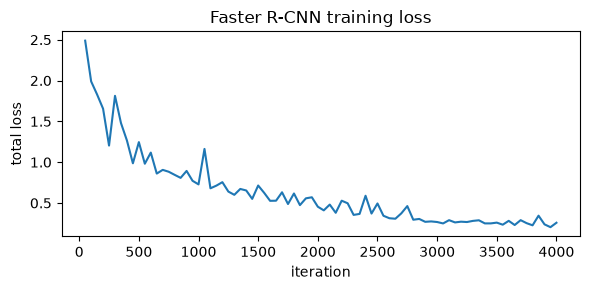

In [37]:
plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, len(loss_history) + 1) * term, loss_history)
plt.xlabel("iteration")
plt.ylabel("total loss")
plt.title("Faster R-CNN training loss")
plt.tight_layout()
plt.show()

## 3.10 결과 확인과 평가

학습한 모델로 **학습에 쓰지 않은** 검증 이미지를 탐지해 봅니다. `model.eval()` 상태에서는 손실 대신 박스, 라벨, 점수를 돌려줍니다. 박스 좌표는 모델 내부 크기 조절이 되돌려진 **원본 이미지 기준**입니다.

여기서 `box_score_thresh=0.05`는 낮은 값이라 후보가 많이 나오므로, 그림에는 점수 0.5가 넘는 박스만 그립니다.

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


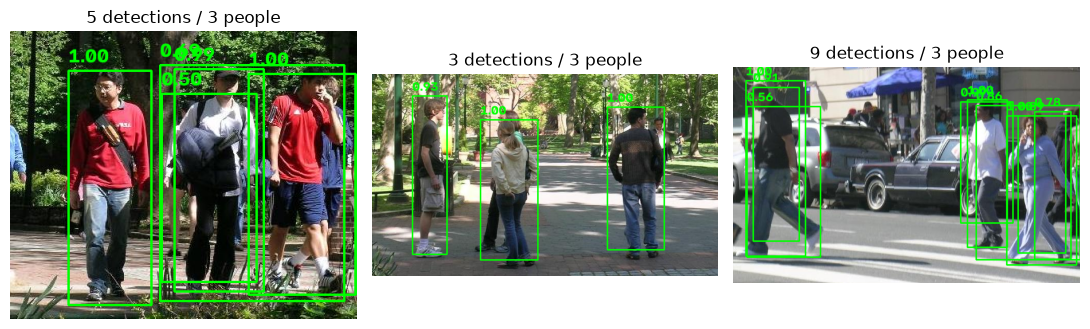

In [38]:
SCORE_THRESHOLD = 0.5
valid_coco = COCO(str(PENN_COCO_ROOT / "valid" / "_annotations.coco.json"))
to_tensor = transforms.ToTensor()


@torch.no_grad()
def detect(image_path: Path) -> dict[str, torch.Tensor]:
    """이미지 한 장을 탐지한 결과를 CPU 텐서로 돌려줍니다."""
    model.eval()
    image = to_tensor(Image.open(image_path).convert("RGB")).to(device)
    return {key: value.cpu() for key, value in model([image])[0].items()}


fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, image_id in zip(axes, valid_coco.getImgIds()[:3]):
    image_path = PENN_COCO_ROOT / "valid" / valid_coco.loadImgs(image_id)[0]["file_name"]
    output = detect(image_path)
    keep = output["scores"] >= SCORE_THRESHOLD
    names = [f"{score:.2f}" for score in output["scores"][keep].tolist()]
    ax.imshow(makeBox(np.array(Image.open(image_path).convert("RGB")), output["boxes"][keep].tolist(), names))
    ax.set_title(f"{int(keep.sum())} detections / {len(valid_coco.getAnnIds(imgIds=image_id))} people")
    ax.axis("off")
plt.tight_layout()
plt.show()

그림만으로는 잘했는지 말하기 어렵습니다. 탐지 성능의 표준 지표는 **mAP(mean Average Precision)** 입니다.

- 점수가 높은 박스부터 차례로 보며, 정답과 IoU가 기준 이상이면 맞은 것으로 칩니다. 이때 정밀도(precision)와 재현율(recall)의 곡선이 그려집니다.
- 그 곡선 아래 넓이가 **AP**입니다. 클래스마다 구해 평균하면 **mAP**입니다.
- `AP@0.5`는 IoU 기준 0.5에서의 값이고, COCO의 대표 지표 `AP@[.50:.95]`는 기준을 0.5에서 0.95까지 올려 가며 평균한 값이라 더 엄격합니다.

`pycocotools`의 `COCOeval`이 이 계산을 해 줍니다. 예측은 COCO 형식(`xywh`)으로 넘겨야 합니다.

In [39]:
predictions = []
for image_id in valid_coco.getImgIds():
    image_path = PENN_COCO_ROOT / "valid" / valid_coco.loadImgs(image_id)[0]["file_name"]
    output = detect(image_path)
    for (x1, y1, x2, y2), score, label in zip(output["boxes"].tolist(), output["scores"].tolist(), output["labels"].tolist()):
        predictions.append({"image_id": image_id, "category_id": label, "bbox": [x1, y1, x2 - x1, y2 - y1], "score": score})

coco_eval = COCOeval(valid_coco, valid_coco.loadRes(predictions), "bbox")
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()
print(f"\nFaster R-CNN  AP@0.5 = {coco_eval.stats[1]:.3f} / AP@[.50:.95] = {coco_eval.stats[0]:.3f}")

Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.01s).
Accumulating evaluation results...
DONE (t=0.00s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.596
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.918
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.692
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.044
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.270
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.639
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.271
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.668
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.691
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

표를 읽어 봅시다. `area=small`의 AP가 `area=large`보다 훨씬 낮습니다. 이 모델의 가장 작은 앵커가 128이고 feature map이 stride 16 하나뿐이라 작은 사람에 약한 구조이며, 4교시의 FPN이 바로 이 문제를 겨냥합니다. 다만 검증 이미지가 34장뿐이어서, 특히 개수가 적은 작은 사람의 값은 흔들림이 큽니다. 다른 데이터에서도 같은 값이 나온다고 기대하면 안 됩니다.

### 실습 5. 검증 데이터의 재현율 계산

`recall_at_iou`를 작성하세요. 검증 데이터의 모든 정답 박스 가운데, 점수가 `score_threshold` 이상인 예측 중 어느 하나와 IoU가 `iou_threshold` 이상인 것의 비율을 구합니다. 기준 점수를 0.3, 0.5, 0.9로 바꿔 가며 값이 어떻게 변하는지 보세요.

In [40]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def recall_at_iou(score_threshold: float, iou_threshold: float = 0.5) -> float:
    """찾아낸 정답 박스의 비율을 계산합니다."""
    found, total = 0, 0
    for image_id in valid_coco.getImgIds():
        image_path = PENN_COCO_ROOT / "valid" / valid_coco.loadImgs(image_id)[0]["file_name"]
        output = detect(image_path)
        pred = output["boxes"][output["scores"] >= score_threshold]
        anns = valid_coco.loadAnns(valid_coco.getAnnIds(imgIds=image_id))
        gt = torch.tensor([xywh_to_xyxy(ann["bbox"]) for ann in anns], dtype=torch.float32)
        total += len(gt)
        if len(pred) > 0:
            found += (box_iou(gt, pred).max(dim=1).values >= iou_threshold).sum().item()
    return found / total


recalls = {t: recall_at_iou(t) for t in [0.3, 0.5, 0.9]}
print(recalls)
assert all(0.0 <= r <= 1.0 for r in recalls.values())
# 기준 점수를 높이면 예측이 줄어들 뿐이므로 재현율이 늘어날 수 없다
assert recalls[0.3] >= recalls[0.5] >= recalls[0.9]
```
</details>

In [41]:
# 다음 교시에서 큰 모델을 또 올리므로 메모리를 비운다. Colab GPU에서 메모리 부족을 막기 위함이다
del model, optimizer, scheduler, backbone, box_head, box_predictor
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
elif torch.backends.mps.is_available():
    torch.mps.empty_cache()

---
# 4교시. You Only Look Once (YOLO)

## 4.1 YOLO에 대해 들어 보셨나요?

- YOLO 시리즈는 **실시간 탐지에서 가장 널리 쓰이는 계열 중 하나**입니다. 빠르고, 쓰기 쉽고, 도구가 잘 갖춰져 있습니다.
- 이미지를 한 번만 보고 박스와 클래스를 **동시에** 내는 1-stage 구조가 YOLO와 함께 널리 퍼졌습니다.
- 처음 연구진(Joseph Redmon 등)은 v3까지 만들었고, Redmon은 2020년에 군사적 이용과 사생활 침해 우려를 이유로 컴퓨터 비전 연구를 그만두겠다고 밝혔습니다. 이후 버전은 다른 연구진과 회사가 이어서 만들고 있어서, 번호가 이어진다고 같은 팀의 후속작은 아닙니다.

참고: [YOLO 설명 글](https://medium.com/curg/you-only-look-once-%EB%8B%A4-%EB%8B%A8%EC%A7%80-%ED%95%9C-%EB%B2%88%EB%A7%8C-%EB%B3%B4%EC%95%98%EC%9D%84-%EB%BF%90%EC%9D%B4%EB%9D%BC%EA%B5%AC-bddc8e6238e2)

> 원본 자료의 "현존 최고의 시리즈", "애플리케이션의 99.9999%"는 근거가 없는 과장이라 위처럼 고쳐 썼습니다. 어떤 모델이 최고인지는 데이터와 조건마다 다르므로 직접 재 봐야 합니다.

2-stage와 비교한 흐름은 다음과 같습니다.

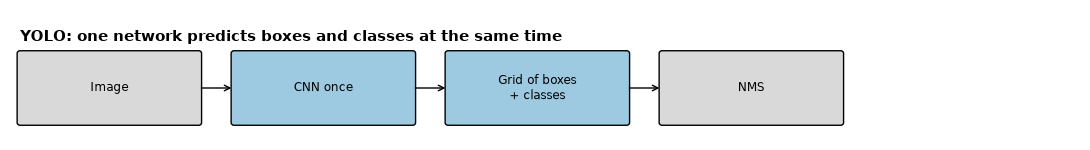

In [42]:
fig, ax = plt.subplots(figsize=(11, 1.6))
draw_flow(ax, 0.4, "YOLO: one network predicts boxes and classes at the same time", [
    ("Image", False), ("CNN once", True), ("Grid of boxes\n+ classes", True), ("NMS", False)])
ax.set_xlim(-0.1, 10.4)
ax.set_ylim(-0.2, 1.3)
ax.axis("off")
plt.tight_layout()
plt.show()

## 4.2 YOLO v1

[논문](https://arxiv.org/abs/1506.02640) · [구조 그림](https://images.velog.io/images/skhim520/post/e3390906-b8f6-454f-adbf-d40a35e407d3/image.png)

- YOLO 시리즈의 시작입니다. GoogLeNet에서 영감을 받은 CNN이 이미지를 S×S 격자의 예측값으로 바꿉니다(논문은 S=7).
- 각 격자 칸은 B개의 바운딩 박스(논문은 B=2)와 박스마다 confidence score를 예측합니다.

$$\text{Confidence} = \Pr(\text{object}) \times \text{IOU}(\text{pred}, \text{truth})$$

- 칸마다 클래스 확률도 예측합니다. 박스가 2개여도 클래스는 칸마다 **한 세트**뿐입니다.
- 객체의 **중심이 들어간 칸**이 그 객체를 책임지고 예측합니다.

VOC(20클래스)에서 출력 크기는 S×S×(B×5 + 20) = 7×7×30입니다. 5는 x, y, w, h, confidence입니다. 그림에서 격자와 책임 칸을 확인해 봅시다.

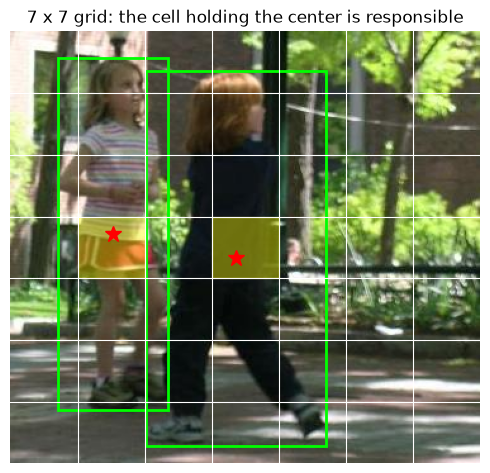

출력 크기: (7, 7, 30) / 박스 수: 98


In [43]:
GRID_SIZE = 7
grid_sample = train_samples[0]
grid_image = Image.open(grid_sample["path"]).convert("RGB")
width, height = grid_image.size

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(grid_image)
for k in range(1, GRID_SIZE):
    ax.axvline(k * width / GRID_SIZE, color="white", lw=0.8)
    ax.axhline(k * height / GRID_SIZE, color="white", lw=0.8)
for obj in grid_sample["objects"]:
    x1, y1, x2, y2 = obj["box"]
    center_x, center_y = (x1 + x2) / 2, (y1 + y2) / 2
    cell_x, cell_y = int(center_x // (width / GRID_SIZE)), int(center_y // (height / GRID_SIZE))
    # 객체의 중심이 들어간 칸만 칠한다. 이 칸이 이 객체를 책임진다
    ax.add_patch(Rectangle((cell_x * width / GRID_SIZE, cell_y * height / GRID_SIZE), width / GRID_SIZE, height / GRID_SIZE, color="yellow", alpha=0.4))
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=2))
    ax.plot(center_x, center_y, "r*", markersize=12)
ax.set_title("7 x 7 grid: the cell holding the center is responsible")
ax.axis("off")
plt.tight_layout()
plt.show()
print("출력 크기:", (GRID_SIZE, GRID_SIZE, 2 * 5 + 20), "/ 박스 수:", GRID_SIZE * GRID_SIZE * 2)

### 단점

- 한 칸에서 한 종류의 객체만 추론할 수 있어 **붙어 있는 작은 객체**를 잘 인식하지 못합니다.
- 박스의 생김새를 데이터에서 직접 배우므로, 학습 데이터에 없던 형태의 박스는 실패하기 쉽습니다.

## 4.3 YOLO v2

[논문](https://arxiv.org/abs/1612.08242) · [구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F95JBN%2FbtqTEM8lVmg%2FW2Fg2DNDUr6J2wfKoA5s3k%2Fimg.png)

- Faster R-CNN의 **앵커**를 가져와, 박스를 격자에서 새로 찾는 대신 앵커를 고치는 형태로 바꿨습니다.
- 다만 앵커의 개수와 가로세로비를 사람이 정하지 않고, 학습 데이터의 박스를 **k-means**로 묶어 정합니다.
- 분류 네트워크 Darknet-19를 쓰고 FC layer를 없애 파라미터 수를 줄였습니다.
- 앵커 기반 박스 예측은 학습 초기에 불안정할 수 있어, 중심 위치에 sigmoid를 씌웁니다. 수식은 다음과 같습니다.

$$b_x = \sigma(t_x) + c_x, \quad b_y = \sigma(t_y) + c_y, \quad b_w = p_w e^{t_w}, \quad b_h = p_h e^{t_h}$$

| 기호 | 뜻 |
|---|---|
| $t_x, t_y, t_w, t_h$ | 네트워크가 내는 값 |
| $c_x, c_y$ | 격자 칸의 왼쪽 위 좌표(칸 단위) |
| $p_w, p_h$ | 앵커의 너비와 높이(칸 단위) |

$\sigma$는 0~1 사이 값이므로 **중심은 자기 칸을 벗어날 수 없습니다**. 그래서 예측이 튀지 않고 학습이 안정됩니다. $e^{t}$는 늘 양수라서 너비와 높이가 음수가 될 일도 없습니다.

수식 그림 출처: [앵커 수식 1](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FrY8Ua%2FbtqV2XmCUtW%2F15eavL05i7jPrYtBD1AIJ0%2Fimg.png) · [앵커 수식 2](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FYMU3b%2FbtqV0Eah13d%2FNEqXsZ0OaAe3uoqUl78wp0%2Fimg.png)

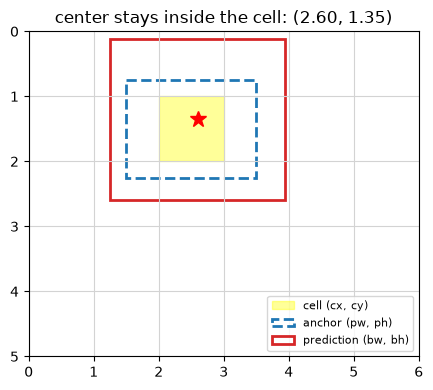

In [44]:
# 위 수식을 그림으로: 앵커(점선)를 네트워크 출력으로 고쳐 예측 박스(실선)를 얻는다
cx, cy, pw, ph = 2, 1, 2.0, 1.5
tx, ty, tw, th = 0.4, -0.6, 0.3, 0.5
sigmoid = lambda t: float(torch.sigmoid(torch.tensor(t)))
bx, by = sigmoid(tx) + cx, sigmoid(ty) + cy
bw, bh = pw * np.exp(tw), ph * np.exp(th)

fig, ax = plt.subplots(figsize=(5, 4))
ax.set_xticks(range(7))
ax.set_yticks(range(6))
ax.grid(True, color="lightgray")
ax.add_patch(Rectangle((cx, cy), 1, 1, color="yellow", alpha=0.4, label="cell (cx, cy)"))
ax.add_patch(Rectangle((cx + 0.5 - pw / 2, cy + 0.5 - ph / 2), pw, ph, fill=False, ls="--", color="tab:blue", lw=2, label="anchor (pw, ph)"))
ax.add_patch(Rectangle((bx - bw / 2, by - bh / 2), bw, bh, fill=False, color="tab:red", lw=2, label="prediction (bw, bh)"))
ax.plot(bx, by, "r*", markersize=12)
ax.set_xlim(0, 6)
ax.set_ylim(5, 0)
ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"center stays inside the cell: ({bx:.2f}, {by:.2f})")
plt.tight_layout()
plt.show()

## 4.4 YOLO v3

[논문](https://arxiv.org/abs/1804.02767) · [구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbNkVM3%2FbtqXxdOyiFH%2FZdEsXc4xtwS6PV7zTSRuuK%2Fimg.png)

오늘날 YOLO의 기본 틀을 갖춘 버전입니다. 초기 연구진이 낸 마지막 YOLO이기도 합니다.

- 박스마다 클래스를 예측하되, softmax 대신 **클래스별로 독립적인 sigmoid**를 씁니다. 그래서 한 박스가 "사람"이면서 "여성"일 수 있는 **Multi-Label 분류**가 가능합니다. (v1은 칸마다 클래스를 냈고, v2는 박스마다 softmax를 썼습니다.)
- FC layer 없는 완전 합성곱 구조에 [FPN(Feature Pyramid Network)](https://arxiv.org/abs/1612.03144)을 더해, 물체의 크기 변화에 강하게 만들었습니다.

### FPN (Feature Pyramid Network)

- YOLO v3의 대표적인 입력 크기는 416×416입니다.
- 입력 이미지에서 자동차가 10×10 픽셀인데 격자가 13×13이면 어떻게 될까요? 416/13 = 32이므로 격자 한 칸은 32×32 픽셀이고, 자동차의 넓이는 칸 하나의 약 1/10밖에 되지 않습니다. 원본의 "1/9"는 어림값이고, 정확히는 100/1024입니다.
- 그렇다고 격자만 촘촘하게 52×52로 쓰면, 네트워크 앞쪽의 feature는 층을 적게 거쳐 **"무엇인지" 판단할 정보가 부족**합니다.
- FPN은 둘을 **조합**합니다. 깊지만 작은 feature(13×13)를 업샘플링하고, 얕지만 큰 feature(26×26, 52×52)와 이어 붙여(concatenate) 세 크기 모두에서 예측합니다.
- 작은 격자(13×13)는 큰 물체를, 큰 격자(52×52)는 작은 물체를 맡습니다. 앵커도 크기별로 3개씩 나눠 줍니다.

FPN 그림 출처: [FPN 구조](https://wikidocs.net/images/page/162976/FPN_10.jpeg)

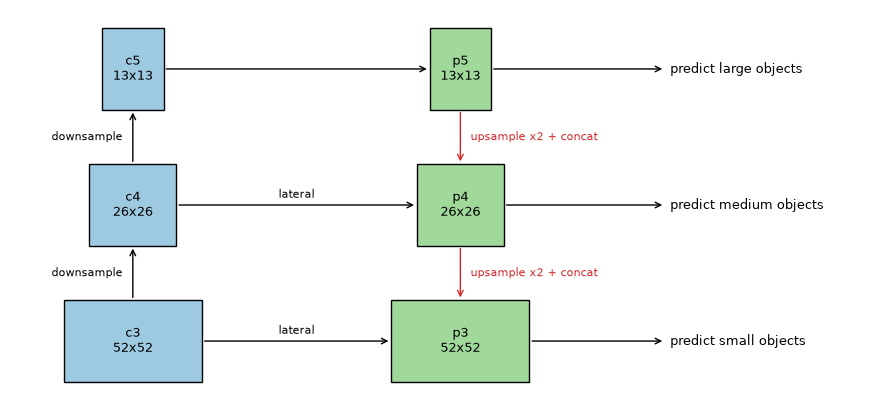

10x10 자동차가 13x13 격자의 한 칸에서 차지하는 넓이: 0.098
10x10 자동차가 52x52 격자의 한 칸에서 차지하는 넓이: 1.562


In [45]:
# YOLO v3의 FPN 구조. 아래 코드의 변수 이름(c3~c5, p3~p5)과 맞췄다
fig, ax = plt.subplots(figsize=(9, 4.2))
levels = [("c3", "p3", 52, "small objects", 0.4), ("c4", "p4", 26, "medium objects", 1.9), ("c5", "p5", 13, "large objects", 3.4)]
for left, right, size, role, y in levels:
    box_size = 0.35 + size / 52
    ax.add_patch(Rectangle((1.0 - box_size / 2, y), box_size, 0.9, fc="#9ecae1", ec="black"))
    ax.text(1.0, y + 0.45, f"{left}\n{size}x{size}", ha="center", va="center", fontsize=9)
    ax.add_patch(Rectangle((4.2 - box_size / 2, y), box_size, 0.9, fc="#a1d99b", ec="black"))
    ax.text(4.2, y + 0.45, f"{right}\n{size}x{size}", ha="center", va="center", fontsize=9)
    ax.annotate("", xy=(4.2 - box_size / 2, y + 0.45), xytext=(1.0 + box_size / 2, y + 0.45), arrowprops={"arrowstyle": "->"})
    ax.text(2.6, y + 0.53, "lateral" if size != 13 else "", ha="center", fontsize=8)
    ax.annotate("", xy=(6.2, y + 0.45), xytext=(4.2 + box_size / 2, y + 0.45), arrowprops={"arrowstyle": "->"})
    ax.text(6.25, y + 0.45, f"predict {role}", va="center", fontsize=9)
for y_from, y_to in [(0.4, 1.9), (1.9, 3.4)]:
    ax.annotate("", xy=(1.0, y_to), xytext=(1.0, y_from + 0.9), arrowprops={"arrowstyle": "->"})
    ax.annotate("", xy=(4.2, y_from + 0.9), xytext=(4.2, y_to), arrowprops={"arrowstyle": "->", "color": "tab:red"})
    ax.text(4.3, (y_from + 0.9 + y_to) / 2, "upsample x2 + concat", color="tab:red", va="center", fontsize=8)
    ax.text(0.9, (y_from + 0.9 + y_to) / 2, "downsample", ha="right", va="center", fontsize=8)
ax.set_xlim(-0.2, 8.3)
ax.set_ylim(0.2, 4.5)
ax.axis("off")
plt.tight_layout()
plt.show()

print("10x10 자동차가 13x13 격자의 한 칸에서 차지하는 넓이:", round(10 * 10 / (416 / 13) ** 2, 3))
print("10x10 자동차가 52x52 격자의 한 칸에서 차지하는 넓이:", round(10 * 10 / (416 / 52) ** 2, 3))

## 4.5 YOLO v3 코드

이론은 중요하지만 글로만 보면 어렵습니다. 코드로 확인해 봅시다. 탐지 모델의 뼈대를 이해하는 데 매우 중요한 코드이니 처음부터 함께 봅니다.

작은 부품에서 시작해 차례로 쌓아 올립니다.

### 기본 Convolution Layer

합성곱, BatchNorm, LeakyReLU를 묶습니다. BatchNorm이 평균을 맞춰 주므로 `bias`는 끕니다.

In [46]:
# basic conv layer
class BasicConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int, padding: int) -> None:
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(x)

### Convolution Layer로 만드는 ResBlock

5강에서 본 잔차 연결입니다. 1×1로 채널을 줄였다가 3×3으로 되돌립니다.

In [47]:
# Residual block
class ResidualBlock(nn.Module):
    def __init__(self, channels: int) -> None:
        super().__init__()

        self.residual = nn.Sequential(
            BasicConv(channels, channels // 2, 1, stride=1, padding=0),
            BasicConv(channels // 2, channels, 3, stride=1, padding=1)
        )

        self.shortcut = nn.Sequential()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_shortcut = self.shortcut(x)
        x_residual = self.residual(x)

        return x_shortcut + x_residual

### FPN Top-Down Layer

업샘플링한 깊은 feature와 얕은 feature를 이어 붙인 뒤 섞어 주는 합성곱 5층입니다.

In [48]:
# FPN의 Top_down layer
class Top_down(nn.Module):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__()

        self.conv = nn.Sequential(
            BasicConv(in_channels, out_channels, 1, stride=1, padding=0),
            BasicConv(out_channels, out_channels * 2, 3, stride=1, padding=1),
            BasicConv(out_channels * 2, out_channels, 1, stride=1, padding=0),
            BasicConv(out_channels, out_channels * 2, 3, stride=1, padding=1),
            BasicConv(out_channels * 2, out_channels, 1, stride=1, padding=0)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(x)

### 각 Feature map이 통과하는 예측 네트워크

여기가 YOLO의 핵심입니다. 합성곱 출력을 `(배치, 앵커 3개, S, S, 25)` 모양으로 바꿔 박스로 풀어 냅니다. 25는 박스 4개 + confidence 1개 + 클래스 20개입니다. `compute_grid_offsets`와 `transform_outputs`가 4.3절 수식을 그대로 구현합니다.

원본에서 고친 곳은 다음과 같습니다.

- 출력 채널이 `75`로 고정되어 다른 클래스 수에서는 에러가 났습니다. 3×(5+클래스 수)로 계산합니다.
- `compute_grid_offsets`가 함수 바깥의 전역 변수 `device`를 읽었습니다. 입력의 장치를 인자로 받습니다.
- `pred_cls` 주석이 "바운딩 박스 좌표"였습니다. 클래스 점수입니다.
- "anchors를 [0~1] 범위로 정규화"라는 주석을 고쳤습니다. stride로 나누면 0~1이 아니라 **칸 단위**가 됩니다.

In [49]:
# YOLO Layer는 13x13, 26x26, 52x52 피쳐맵에서 예측을 수행합니다.
class YOLOLayer(nn.Module):
    def __init__(self, channels: int, anchors: list[tuple[int, int]], num_classes: int = 20, img_dim: int = 416) -> None:
        super().__init__()
        self.anchors = anchors # three anchors per YOLO Layer
        self.num_anchors = len(anchors) # 3
        self.num_classes = num_classes # VOC classes 20
        self.img_dim = img_dim # 입력 이미지 크기 416
        self.grid_size = 0

        # 예측을 수행하기 전, smooth conv layer 입니다.
        # 앵커마다 (x, y, w, h, confidence, 클래스 점수들)을 낸다. VOC면 3 x 25 = 75
        self.conv = nn.Sequential(
            BasicConv(channels, channels * 2, 3, stride=1, padding=1),
            nn.Conv2d(channels * 2, self.num_anchors * (5 + num_classes), 1, stride=1, padding=0)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv(x)

        # prediction
        # x: batch, channels, H, W
        batch_size = x.size(0)
        grid_size = x.size(2) # S = 13 or 26 or 52

        prediction = x.view(batch_size, self.num_anchors, self.num_classes + 5,
                            grid_size, grid_size) # shape = (batch, 3, 25, S, S)

        # shape change (batch, 3, 25, S, S) -> (batch, 3, S, S, 25)
        prediction = prediction.permute(0, 1, 3, 4, 2)
        prediction = prediction.contiguous()

        obj_score = torch.sigmoid(prediction[..., 4]) # Confidence: 객체가 있으면 1, 없으면 0에 가깝게 학습
        pred_cls = torch.sigmoid(prediction[..., 5:]) # 클래스 점수. v3는 클래스마다 독립적인 sigmoid를 쓴다

        # grid_size 갱신
        if grid_size != self.grid_size:
            # grid_size를 갱신하고, transform_outputs 함수를 위해 anchor 박스를 전처리 합니다.
            self.compute_grid_offsets(grid_size, x.device)

        # calculate bounding box coordinates
        pred_boxes = self.transform_outputs(prediction)

        # output shape(batch, num_anchors x S x S, 25)
        # ex) at 13x13 -> [batch, 507, 25], at 26x26 -> [batch, 2028, 25], at 52x52 -> [batch, 8112, 25]
        # 최종적으로 YOLO는 10647개의 바운딩박스를 예측합니다.
        output = torch.cat((pred_boxes.view(batch_size, -1, 4),
                    obj_score.view(batch_size, -1, 1),
                    pred_cls.view(batch_size, -1, self.num_classes)), -1)
        return output


    # grid_size를 갱신하고, transform_outputs 함수를 위해 anchor 박스를 전처리 합니다.
    def compute_grid_offsets(self, grid_size: int, device: torch.device) -> None:
        self.grid_size = grid_size # ex) 13, 26, 52
        self.stride = self.img_dim / self.grid_size

        # cell index 생성
        # transform_outputs 함수에서 바운딩 박스의 x, y좌표를 예측할 때 사용합니다.
        # 1, 1, S, S
        self.grid_x = torch.arange(grid_size, device=device).repeat(1, 1, grid_size, 1).type(torch.float32)
        # 1, 1, S, S
        self.grid_y = torch.arange(grid_size, device=device).repeat(1, 1, grid_size, 1).transpose(3, 2).type(torch.float32)

        # anchors를 stride로 나눠 격자 칸 단위로 바꾼다. 수식의 pw, ph가 칸 단위이기 때문이다
        scaled_anchors = [(a_w / self.stride, a_h / self.stride) for a_w, a_h in self.anchors]
        # tensor로 변환
        self.scaled_anchors = torch.tensor(scaled_anchors, device=device, dtype=torch.float32)

        # transform_outputs 함수에서 바운딩 박스의 w, h를 예측할 때 사용합니다.
        # shape=(3,2) -> (1, 3, 1, 1)
        self.anchor_w = self.scaled_anchors[:, 0:1].view((1, self.num_anchors, 1, 1))
        self.anchor_h = self.scaled_anchors[:, 1:2].view((1, self.num_anchors, 1, 1))


    # 예측한 바운딩 박스 좌표를 계산하는 함수입니다.
    def transform_outputs(self, prediction: torch.Tensor) -> torch.Tensor:
        # prediction = (batch, num_anchors, S, S, coordinates + classes)
        device = prediction.device
        x = torch.sigmoid(prediction[..., 0]) # sigmoid(box x), 예측값을 sigmoid로 감싸서 [0~1] 범위
        y = torch.sigmoid(prediction[..., 1]) # sigmoid(box y), 예측값을 sigmoid로 감싸서 [0~1] 범위
        w = prediction[..., 2] # 예측한 바운딩 박스 너비
        h = prediction[..., 3] # 예측한 바운딩 박스 높이

        pred_boxes = torch.zeros_like(prediction[..., :4]).to(device)
        pred_boxes[..., 0] = x.data + self.grid_x # sigmoid(box x) + cell x 좌표
        pred_boxes[..., 1] = y.data + self.grid_y # sigmoid(box y) + cell y 좌표
        pred_boxes[..., 2] = torch.exp(w.data) * self.anchor_w
        pred_boxes[..., 3] = torch.exp(h.data) * self.anchor_h

        return pred_boxes * self.stride

### 3개의 Feature map 결과를 합치는 최종 구현체

Darknet-53 backbone과 FPN을 잇습니다. 채널 수를 맞춰 보면 구조가 이해됩니다. `topdown_2`의 입력 768은 업샘플링한 `p5`(512)와 `lateral_1`로 줄인 `c4`(256)의 합입니다.

원본 논문의 구현은 깊은 쪽 feature를 먼저 1×1로 줄이고 업샘플링합니다. 이 코드는 얕은 쪽(lateral)을 줄입니다. 합친 채널 수는 같고, 기본 구조를 이해하는 데는 지장이 없습니다.

원본은 `DarkNet`이 `num_classes`를 받아 놓고 `YOLOLayer`에 넘기지 않아 늘 20클래스로 동작했습니다. 넘기도록 고쳤습니다.

In [50]:
class DarkNet(nn.Module):
    def __init__(self, anchors: list[list[tuple[int, int]]], num_blocks: list[int] = [1, 2, 8, 8, 4], num_classes: int = 20) -> None:
        super().__init__()

        # DarkNet, feature extractor
        self.conv1 = BasicConv(3, 32, 3, stride=1, padding=1)             # 416x416
        self.res_block_1 = self._make_residual_block(64, num_blocks[0])   # 208x208
        self.res_block_2 = self._make_residual_block(128, num_blocks[1])  # 104x104
        self.res_block_3 = self._make_residual_block(256, num_blocks[2])  # 52x52, FPN lateral connection
        self.res_block_4 = self._make_residual_block(512, num_blocks[3])  # 26x26, FPN lateral connection
        self.res_block_5 = self._make_residual_block(1024, num_blocks[4]) # 13x13, Top layer

        # FPN Top down
        self.topdown_1 = Top_down(1024, 512)
        self.topdown_2 = Top_down(768, 256)
        self.topdown_3 = Top_down(384, 128)

        # FPN lateral connection
        # 차원 축소를 위해 사용합니다.
        self.lateral_1 = BasicConv(512, 256, 1, stride=1, padding=0)
        self.lateral_2 = BasicConv(256, 128, 1, stride=1, padding=0)

        # prediction, 13x13, 26x26, 52x52 피쳐맵에서 예측을 수행합니다.
        # 격자가 성긴 층일수록 큰 물체를 맡으므로 큰 앵커를 준다
        self.yolo_1 = YOLOLayer(512, anchors=anchors[2], num_classes=num_classes) # 13x13
        self.yolo_2 = YOLOLayer(256, anchors=anchors[1], num_classes=num_classes) # 26x26
        self.yolo_3 = YOLOLayer(128, anchors=anchors[0], num_classes=num_classes) # 52x52

        self.upsample = nn.Upsample(scale_factor=2)


    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, list[torch.Tensor]]:
        # DarkNet, feature extractor
        x = self.conv1(x)
        c1 = self.res_block_1(x)
        c2 = self.res_block_2(c1)
        c3 = self.res_block_3(c2)
        c4 = self.res_block_4(c3)
        c5 = self.res_block_5(c4)

        # FPN Top-down, Upsample and lateral connection
        p5 = self.topdown_1(c5)
        p4 = self.topdown_2(torch.cat((self.upsample(p5), self.lateral_1(c4)), 1))
        p3 = self.topdown_3(torch.cat((self.upsample(p4), self.lateral_2(c3)), 1))

        # prediction
        yolo_1 = self.yolo_1(p5) # 13x13
        yolo_2 = self.yolo_2(p4) # 26x26
        yolo_3 = self.yolo_3(p3) # 52x52

        return torch.cat((yolo_1, yolo_2, yolo_3), 1), [yolo_1, yolo_2, yolo_3]

    def _make_residual_block(self, in_channels: int, num_block: int) -> nn.Sequential:
        blocks = []
        # down sample
        blocks.append(BasicConv(in_channels // 2, in_channels, 3, stride=2, padding=1))
        for i in range(num_block):
            blocks.append(ResidualBlock(in_channels))
        return nn.Sequential(*blocks)

### 입력을 넣어 출력 크기 확인

무작위 입력을 넣어 출력 크기가 설명대로인지 확인합니다. 앵커는 논문의 COCO용 9개를 작은 것부터 3개씩 묶은 값입니다. (원본의 제목은 "박스로 변환하는 코드"였지만, 변환은 앞의 `transform_outputs`가 하고 이 셀은 크기 확인입니다.)

세 층의 박스를 합치면 3×(13² + 26² + 52²) = 10647개입니다.

In [51]:
anchors = [[(10, 13), (16, 30), (33, 23)], [(30, 61), (62, 45), (59, 119)], [(116, 90), (156, 198), (373, 326)]]
x = torch.randn(1, 3, 416, 416).to(device)
with torch.no_grad():
    model = DarkNet(anchors).to(device)
    model.eval()   # 배치 크기 1이라 BatchNorm을 평가 모드로 둔다
    output_cat, output = model(x)
    print(output_cat.size())
    print(output[0].size(), output[1].size(), output[2].size())
print(f"파라미터: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

torch.Size([1, 10647, 25])
torch.Size([1, 507, 25]) torch.Size([1, 2028, 25]) torch.Size([1, 8112, 25])
파라미터: 61.6M


이 모델로 바로 학습할 수는 없습니다. 학습하려면 YOLO 전용 손실이 필요하고, `transform_outputs`가 `.data`로 계산 그래프를 끊어 박스 값으로는 역전파가 되지 않기 때문입니다. 지금 코드는 **구조와 박스 디코딩**을 이해하기 위한 것입니다. 학습은 5교시에서 검증된 패키지로 합니다.

**Q. 416×416 대신 608×608을 넣으면 출력 박스 수는 몇 개일까요? FC layer가 없다는 사실이 왜 여기서 중요할까요?**

<details><summary>답</summary>

격자가 19, 38, 76이 되므로 3×(19² + 38² + 76²) = 22743개입니다. FC layer는 입력 크기가 고정되어야 하지만 합성곱은 그렇지 않아서, 32의 배수이기만 하면 어떤 크기든 같은 모델로 처리할 수 있습니다. 다만 위 코드의 `img_dim`도 함께 바꿔 주어야 stride가 맞습니다.
</details>

### 실습 6. 박스 디코딩 직접 계산

`decode_box`를 작성하세요. 네트워크 출력 $t_x, t_y, t_w, t_h$, 칸 좌표 $c_x, c_y$, 앵커 크기 `anchor_w`, `anchor_h`(픽셀), `stride`를 받아 **픽셀 단위** 박스 `(중심 x, 중심 y, 너비, 높이)`를 돌려줍니다. 그다음 `YOLOLayer.transform_outputs`와 값이 같은지 비교합니다. 또 `DarkNet(anchors, num_classes=3)`의 출력 크기도 확인하세요.

In [52]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def decode_box(tx: float, ty: float, tw: float, th: float, cx: int, cy: int,
               anchor_w: float, anchor_h: float, stride: float) -> tuple[float, float, float, float]:
    """네트워크 출력을 픽셀 단위 박스로 풉니다."""
    center_x = (torch.sigmoid(torch.tensor(tx)).item() + cx) * stride
    center_y = (torch.sigmoid(torch.tensor(ty)).item() + cy) * stride
    # 앵커가 이미 픽셀 단위이므로 stride를 다시 곱하지 않는다
    return center_x, center_y, anchor_w * np.exp(tw), anchor_h * np.exp(th)


layer = YOLOLayer(512, anchors=anchors[2])
layer.compute_grid_offsets(13, torch.device("cpu"))
fake_prediction = torch.zeros(1, 3, 13, 13, 25)
fake_prediction[0, 1, 4, 7, :4] = torch.tensor([0.4, -0.6, 0.3, 0.5])   # 앵커 1번, y칸 4, x칸 7
decoded = layer.transform_outputs(fake_prediction)[0, 1, 4, 7].tolist()
mine = decode_box(0.4, -0.6, 0.3, 0.5, cx=7, cy=4, anchor_w=156, anchor_h=198, stride=32)
assert np.allclose(decoded, mine, atol=1e-3), (decoded, mine)
print("직접 계산:", np.round(mine, 2), "/ YOLOLayer:", np.round(decoded, 2))

with torch.no_grad():
    small_model = DarkNet(anchors, num_classes=3).to(device).eval()
    assert small_model(x)[0].shape == (1, 10647, 8)   # 박스 4 + confidence 1 + 클래스 3
print("3클래스 출력:", small_model(x)[0].shape)
del small_model
```
</details>

In [53]:
# 5교시 전에 메모리를 비운다
del model, x, output_cat, output
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
elif torch.backends.mps.is_available():
    torch.mps.empty_cache()

---
# 5교시. YOLO 직접 써 보기

## 5.1 사전학습 모델 불러오기

직접 만든 코드 대신, 다른 사람이 만들어 둔 구현을 불러와 동작시켜 봅니다. YOLOv3보다 뒤에 나온 YOLOv5를 씁니다. YOLOv5는 Darknet을 CSP-Darknet으로 바꾸고, 같은 구조를 크기별(n, s, m, l, x)로 나눠 제공합니다. CSP-Darknet은 연산량을 줄인 backbone입니다. 지금 단계에서는 YOLOv3와 "backbone, FPN 계열 neck, 여러 크기에서의 예측"이라는 뼈대가 같다고 이해하면 충분합니다.

예전에는 YOLOv5 저장소를 `git clone`해서 `requirements`를 설치한 뒤 `torch.hub`로 불러왔습니다. 지금은 같은 회사의 **`ultralytics` 패키지** 하나로 설치, 추론, 학습을 모두 할 수 있습니다. 저장소의 코드를 받아 실행할 필요가 없어 관리도 쉽습니다.

여기서 쓰는 `yolov5su.pt`는 YOLOv5s를 ultralytics 패키지용으로 개선한 모델입니다. 이름의 `u`는 예측부를 **앵커를 쓰지 않는(anchor-free) 방식**으로 바꿨다는 표시입니다. 오늘 배운 앵커 기반 YOLOv5와 이 점이 다르고, 쓰는 방법에는 차이가 없습니다.

In [54]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

model = YOLO("yolov5su.pt")
print("클래스 수:", len(model.names), "/ 예:", list(model.names.values())[:5])
print(f"파라미터: {sum(p.numel() for p in model.model.parameters()) / 1e6:.1f}M")

클래스 수: 80 / 예: ['person', 'bicycle', 'car', 'motorcycle', 'airplane']
파라미터: 9.2M


인터넷의 이미지를 내려받아 탐지해 봅니다. 사이트 사정으로 내려받지 못하면 패키지에 들어 있는 예제 이미지를 씁니다.

In [55]:
# 다운받을 이미지 url
url = "https://content.gallup.com/origin/gallupinc/GallupSpaces/Production/Cms/TGBCMS/iy1ex3cookmf9cme5qlnxa.jpg"

# time check
start = time.time()

try:
    # 응답이 없을 때 멈추지 않도록 시간 제한을 둔다
    with urllib.request.urlopen(url, timeout=30) as response, open("test.jpg", "wb") as f:
        shutil.copyfileobj(response, f)
    test_image_path = Path("test.jpg")
except OSError as error:
    print("내려받기 실패, 예제 이미지를 씁니다:", error)
    test_image_path = ASSETS / "bus.jpg"

# 이미지 다운로드 시간 체크
print(f"{time.time() - start:.2f} s")

# 저장된 이미지 확인
img = Image.open(test_image_path).convert("RGB")
print(img.size)

0.20 s
(1840, 1040)


5 persons, 1 bottle, 3 cups, 1 hot dog, 1 cell phone, 


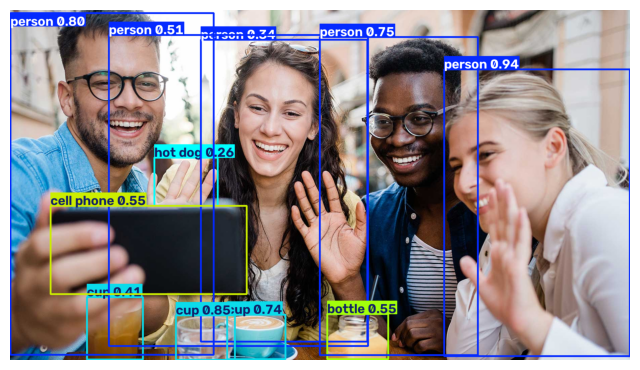

In [56]:
results = model(img)
print(results[0].verbose())      # 원본의 results.print()에 해당

# plot()은 박스를 그린 BGR 이미지를 돌려주므로 RGB로 뒤집어 보여 준다
plt.figure(figsize=(8, 5))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis("off")
plt.show()

## 5.2 내 데이터로 YOLO 전이학습

마지막으로 가지고 있는 데이터로 YOLO를 전이학습해 봅니다. COCO 80클래스로 학습된 모델을 가져와 사람 한 클래스만 찾도록 다시 학습합니다.

원본의 순서를 그대로 따라갑니다.

1. 라벨링한 데이터를 `dataset/train/images/`에 저장합니다.
2. 예전 YOLOv5에서는 `models/yolov5s.yaml`을 열어 클래스 수 `nc`를 직접 고쳤습니다. **ultralytics에서는 데이터 설정의 클래스 수를 보고 마지막 층을 저절로 바꿔 주므로 이 단계가 필요 없습니다.**

YOLO 라벨은 이미지마다 텍스트 파일 하나이고, 한 줄이 객체 하나입니다. 숫자는 `클래스 중심x 중심y 너비 높이`이고 이미지 크기로 나눈 0~1 값입니다(1.2절 표). 라벨 폴더는 이미지 폴더 경로의 `images`를 `labels`로 바꾼 곳이어야 합니다. Roboflow에서 Format을 YOLO로 내보내면 이 구조로 받을 수 있습니다. 여기서는 Penn-Fudan을 직접 변환합니다.

In [57]:
YOLO_ROOT = (DATA_ROOT / "PennFudan_yolo").resolve()   # txt 안에 절대 경로를 쓰므로 미리 풀어 둔다


def to_yolo_label(box: list[int], image_width: int, image_height: int) -> tuple[float, float, float, float]:
    """xyxy 픽셀 박스를 YOLO 형식(중심과 크기, 0~1)으로 바꿉니다."""
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2 / image_width, (y1 + y2) / 2 / image_height, (x2 - x1) / image_width, (y2 - y1) / image_height)


(YOLO_ROOT / "train" / "images").mkdir(parents=True, exist_ok=True)
(YOLO_ROOT / "train" / "labels").mkdir(parents=True, exist_ok=True)
for sample in samples:
    shutil.copy(sample["path"], YOLO_ROOT / "train" / "images" / sample["path"].name)
    lines = [
        "0 " + " ".join(f"{value:.6f}" for value in to_yolo_label(obj["box"], sample["width"], sample["height"]))
        for obj in sample["objects"]
    ]
    (YOLO_ROOT / "train" / "labels" / f"{sample['path'].stem}.txt").write_text("\n".join(lines) + "\n")

# Roboflow가 내보낼 때 함께 주는 data.yaml과 같은 내용을 만들어 둔다
with open(YOLO_ROOT / "data.yaml", "w") as f:
    yaml.safe_dump({"train": "train/images", "val": "train/images", "nc": 1, "names": ["person"]}, f)

print((YOLO_ROOT / "train" / "labels" / f"{samples[0]['path'].stem}.txt").read_text())

0 0.412343 0.570896 0.255814 0.466418
0 0.853309 0.611940 0.207513 0.589552



### 저장 경로의 이미지 목록 불러오기

Penn-Fudan 이미지는 PNG입니다. 내 데이터가 JPG라면 패턴을 `*.jpg`로 바꾸세요.

In [58]:
img_list = glob(str(YOLO_ROOT / "train" / "images" / "*.png"))

print(len(img_list))

170


### 학습 데이터와 검증 데이터 나누기

3교시의 분할과는 다르게 나뉘므로, Faster R-CNN과 뒤의 YOLO 결과를 숫자로 곧바로 비교하면 안 됩니다. 입력 크기와 학습량도 다릅니다.

In [59]:
train_img_list, val_img_list = train_test_split(img_list, test_size=0.2, random_state=2000)

print(len(train_img_list), len(val_img_list))

136 34


### 나눈 목록 저장

In [60]:
with open(YOLO_ROOT / "train.txt", "w") as f:
    f.write("\n".join(train_img_list) + "\n")

with open(YOLO_ROOT / "val.txt", "w") as f:
    f.write("\n".join(val_img_list) + "\n")

### 데이터 설정 파일 만들기 (data.yaml)

`train`과 `val`이 방금 만든 목록을 가리키게 고칩니다. 원본의 `yaml.load(f)`는 지금의 PyYAML에서 `Loader` 인자가 없어 에러가 납니다. 파일의 임의 코드를 실행하지 않는 `yaml.safe_load`를 씁니다.

In [61]:
with open(YOLO_ROOT / "data.yaml", "r") as f:
    data = yaml.safe_load(f)

print(data)

data["train"] = str(YOLO_ROOT / "train.txt")
data["val"] = str(YOLO_ROOT / "val.txt")

with open(YOLO_ROOT / "data.yaml", "w") as f:
    yaml.safe_dump(data, f)

# 절대 경로는 환경마다 다르므로 파일 이름만 찍어 확인한다
print({**data, "train": Path(data["train"]).name, "val": Path(data["val"]).name})

{'names': ['person'], 'nc': 1, 'train': 'train/images', 'val': 'train/images'}
{'names': ['person'], 'nc': 1, 'train': 'train.txt', 'val': 'val.txt'}


### 학습

원본 명령 `python train.py --img 416 --batch 16 --epochs 50 --data data.yaml --cfg yolov5s.yaml --weights yolov5s.pt --name yolov5s_results`와 같은 설정을 ultralytics 함수로 씁니다. 이미지 416, 배치 16, 50 epoch입니다.

노트북이 로그로 가득 차지 않게 맨 앞에서 `YOLO_VERBOSE=False`로 로그를 줄이고, 10 epoch마다 한 줄씩 직접 출력합니다. 이미 학습한 결과가 있으면 다시 학습하지 않으니, **다시 학습하려면 `runs/yolo` 폴더를 지우세요**.

In [62]:
YOLO_RUN_DIR = Path("runs/yolo").resolve()
YOLO_BEST = YOLO_RUN_DIR / "yolov5s_results" / "weights" / "best.pt"
YOLO_EPOCHS = 50
YOLO_PRINT_EVERY = 10


def print_progress(trainer) -> None:
    """에폭이 끝날 때 호출되어, 정해진 주기마다 검증 성능을 한 줄로 출력합니다."""
    epoch = trainer.epoch + 1
    if epoch % YOLO_PRINT_EVERY == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | mAP50 {trainer.metrics['metrics/mAP50(B)']:.3f} | mAP50-95 {trainer.metrics['metrics/mAP50-95(B)']:.3f}")


if YOLO_BEST.exists():
    print("이미 학습한 결과가 있어 건너뜁니다:", YOLO_BEST.name)
else:
    model = YOLO("yolov5su.pt")
    model.add_callback("on_fit_epoch_end", print_progress)
    # ultralytics는 cuda 장치를 번호로 받는다
    train_device = 0 if device.type == "cuda" else device.type
    model.train(data=str(YOLO_ROOT / "data.yaml"), imgsz=416, batch=16, epochs=YOLO_EPOCHS, device=train_device,
                project=str(YOLO_RUN_DIR), name="yolov5s_results", exist_ok=True, seed=1729)

epoch   1 | mAP50 0.975 | mAP50-95 0.731


epoch  10 | mAP50 0.836 | mAP50-95 0.531


epoch  20 | mAP50 0.967 | mAP50-95 0.749


epoch  30 | mAP50 0.972 | mAP50-95 0.703


epoch  40 | mAP50 0.986 | mAP50-95 0.827


epoch  50 | mAP50 0.987 | mAP50-95 0.838


학습 곡선은 저장된 `results.csv`에서 그립니다. 학습 손실과 함께 검증 성능을 보세요. 사전학습 모델에서 출발하므로 첫 에폭부터 성능이 높을 수 있고, 처음 몇 에폭은 학습률을 천천히 올리는 warmup 구간이라 성능이 잠시 흔들릴 수 있습니다. 그래서 첫 에폭 숫자만 보고 판단하지 말고 곡선 전체를 봅니다.

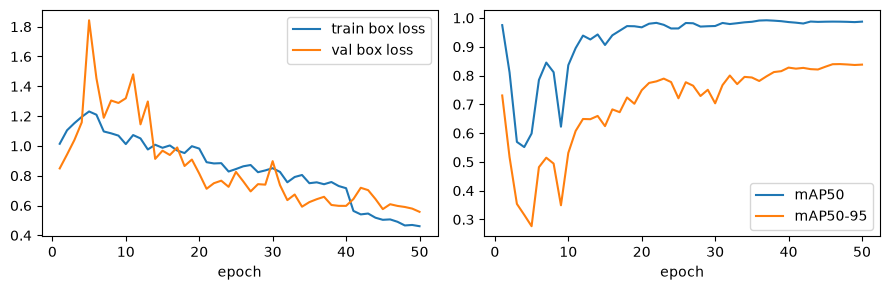

저장된 에폭 수: 50


In [63]:
with open(YOLO_RUN_DIR / "yolov5s_results" / "results.csv") as f:
    rows = [{key.strip(): float(value) for key, value in row.items()} for row in csv.DictReader(f)]
epochs_axis = [row["epoch"] for row in rows]

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(epochs_axis, [row["train/box_loss"] for row in rows], label="train box loss")
axes[0].plot(epochs_axis, [row["val/box_loss"] for row in rows], label="val box loss")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(epochs_axis, [row["metrics/mAP50(B)"] for row in rows], label="mAP50")
axes[1].plot(epochs_axis, [row["metrics/mAP50-95(B)"] for row in rows], label="mAP50-95")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.show()
print("저장된 에폭 수:", len(rows))

### 결과 확인

학습이 끝나면 가장 좋았던 가중치가 `weights/best.pt`에 저장됩니다. 원본은 여기서 학습 결과가 아니라 앞에서 불러온 COCO 사전학습 모델 `model`을 그대로 썼습니다. 그러면 학습 결과를 확인하는 것이 아닙니다. **`best.pt`를 불러와** 평가합니다.

In [64]:
best_model = YOLO(str(YOLO_BEST))
metrics = best_model.val(data=str(YOLO_ROOT / "data.yaml"), imgsz=416, plots=False, device=0 if device.type == "cuda" else device.type)
print(f"YOLO  mAP50 = {metrics.box.map50:.3f} / mAP50-95 = {metrics.box.map:.3f}")
print("클래스:", best_model.names)

YOLO  mAP50 = 0.987 / mAP50-95 = 0.841
클래스: {0: 'person'}


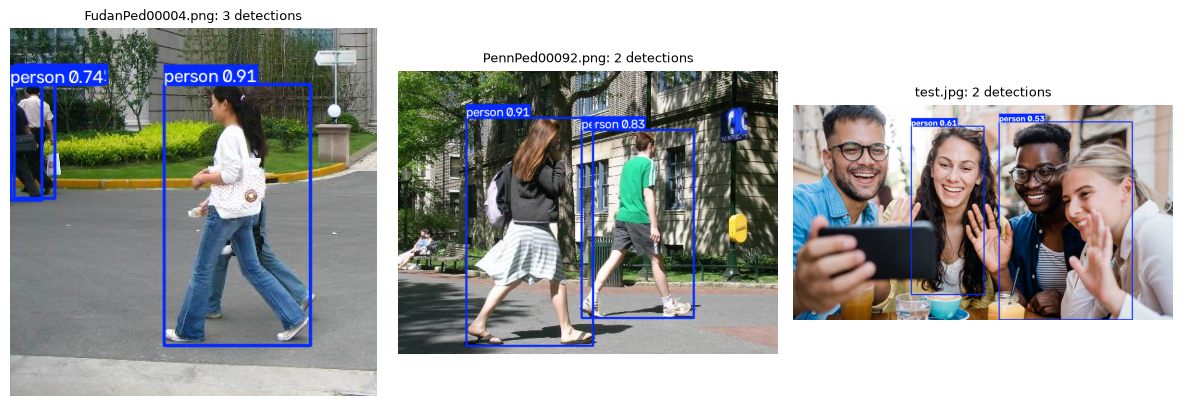

In [65]:
# 학습에 쓰지 않은 검증 이미지와, 앞에서 내려받은 일반 사진을 탐지한다
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image_path in zip(axes, [sorted(val_img_list)[0], sorted(val_img_list)[-1], test_image_path]):
    result = best_model(Image.open(image_path).convert("RGB"))[0]
    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(f"{Path(image_path).name[:18]}: {len(result.boxes)} detections", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 동영상 탐지

원본은 `detect.py --weights best.pt --img 1280 --conf 0.4 --source 동영상.mp4`로 Drive에 있는 동영상을 탐지했습니다. `predict`의 `source`에 동영상 경로를 주면 같은 일을 합니다. 내 동영상이 없어도 돌아가도록, 검증 이미지로 짧은 영상을 만들어 씁니다.

`stream=True`를 주면 프레임 결과를 메모리에 쌓지 않고 하나씩 돌려줘서 긴 동영상에서도 메모리가 넘치지 않습니다. `conf`는 최소 점수이고, `imgsz=1280`은 추론 입력 크기입니다. 416으로 학습한 모델이라도 합성곱 구조라서 다른 크기로 추론할 수 있습니다.

In [66]:
VIDEO_SIZE = (640, 480)
VIDEO_FPS = 5
VIDEO_FRAMES = 20
video_path = "demo.mp4"

writer_video = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*"mp4v"), VIDEO_FPS, VIDEO_SIZE)
for image_path in sorted(val_img_list)[:VIDEO_FRAMES]:
    frame = cv2.imread(image_path)
    writer_video.write(cv2.resize(frame, VIDEO_SIZE))
writer_video.release()

detections_per_frame = [
    len(result.boxes)
    for result in best_model.predict(source=video_path, imgsz=1280, conf=0.4, stream=True, verbose=False)
]
print("프레임 수:", len(detections_per_frame))
print("프레임별 탐지 수:", detections_per_frame)

프레임 수: 20
프레임별 탐지 수: [3, 7, 4, 0, 2, 2, 8, 3, 2, 5, 5, 1, 5, 6, 6, 1, 2, 4, 3, 3]


### 실습 7. YOLO 라벨을 픽셀 박스로 되돌리기

`yolo_to_xyxy`를 작성하세요. YOLO 라벨 한 줄의 값(중심 x, 중심 y, 너비, 높이)과 이미지 크기를 받아 `xyxy` 픽셀 박스를 돌려줍니다. 실제 라벨 파일을 읽어 `samples`의 원래 박스와 1픽셀 이내로 같은지 확인하세요. 또 `best_model`의 `conf`를 0.25, 0.5, 0.9로 바꿔 검증 이미지 한 장의 탐지 수가 어떻게 변하는지 보세요.

In [67]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def yolo_to_xyxy(label: list[float], image_width: int, image_height: int) -> list[float]:
    """YOLO 형식(0~1)을 xyxy 픽셀 박스로 되돌립니다."""
    center_x, center_y, w, h = label
    return [(center_x - w / 2) * image_width, (center_y - h / 2) * image_height,
            (center_x + w / 2) * image_width, (center_y + h / 2) * image_height]


check_sample = samples[0]
label_path = YOLO_ROOT / "train" / "labels" / f"{check_sample['path'].stem}.txt"
label_lines = label_path.read_text().strip().splitlines()
assert len(label_lines) == len(check_sample["objects"])
for line, obj in zip(label_lines, check_sample["objects"]):
    values = [float(v) for v in line.split()[1:]]
    restored = yolo_to_xyxy(values, check_sample["width"], check_sample["height"])
    assert np.allclose(restored, obj["box"], atol=1.0), (restored, obj["box"])

counts = {conf: len(best_model.predict(sorted(val_img_list)[0], conf=conf, verbose=False)[0].boxes) for conf in [0.25, 0.5, 0.9]}
print(counts)
# 기준 점수를 높이면 살아남는 박스는 줄어들기만 한다
assert counts[0.25] >= counts[0.5] >= counts[0.9]
```
</details>

---
# 오늘의 요약

- **탐지**는 객체마다 클래스와 박스를 맞히는 문제입니다. 박스 형식(`xyxy`, COCO `xywh`, YOLO 정규화)을 헷갈리면 조용히 틀린 결과가 나옵니다.
- **IoU**는 박스 겹침의 정도, **NMS**는 겹친 박스 정리, **mAP**는 전체 성능 지표입니다.
- **COCO 형식**은 `images`, `annotations`, `categories`로 된 JSON이고, `pycocotools`로 읽고 평가합니다.
- **나만의 Dataset**에서는 이미지를 변환할 때 박스도 함께 바꾸고, 박스 수가 다른 문제는 패딩이나 `collate_fn`으로 풉니다. 박스를 꼭 그려서 확인합니다.
- **R-CNN → Fast R-CNN → Faster R-CNN**은 CNN을 한 번만 돌리고(RoI Pooling), 제안 단계까지 신경망으로 바꾼(RPN과 앵커) 역사입니다.
- **YOLO**는 박스와 클래스를 한 번에 냅니다. v2가 앵커와 안정적인 디코딩을, v3가 FPN으로 여러 크기의 예측과 독립 sigmoid를 더했습니다.
- **ultralytics**로 사전학습 모델 추론과 전이학습을 몇 줄로 할 수 있습니다. 결과는 반드시 학습에 쓰지 않은 데이터와 `best.pt`로 확인합니다.

# 숙제

1. **내 데이터로 끝까지**: Roboflow에서 관심 있는 물체를 30장 이상 라벨링하고 YOLO 형식으로 내려받아 5.2절을 따라 학습해 보세요. 변환 셀 대신 내려받은 폴더를 `YOLO_ROOT`로 지정하고, 이미지 패턴을 `*.jpg`로 바꾸고, 앞선 결과가 남아 있으면 `runs/yolo`를 지웁니다. `best.pt`로 학습에 쓰지 않은 사진을 탐지합니다.
2. **손실 비중 실험**: `Total_Loss`의 `10 * loss_rpn_box_reg`를 `1 * loss_rpn_box_reg`로 바꿔 Faster R-CNN을 다시 학습하고 mAP를 비교하세요. (`checkpoints` 폴더를 먼저 지우세요.)
3. **모델 비교**: 3교시와 5교시의 검증 분할을 같게 맞춘 뒤, 같은 이미지로 Faster R-CNN과 YOLO의 AP@0.5와 추론 시간을 표로 비교하세요.
4. **`box_nms_thresh` 실험**: 3.8절의 `box_nms_thresh=0.7`을 0.3으로 낮추면 그림과 mAP가 어떻게 달라지는지 확인하고 까닭을 설명하세요.
5. **논문 읽기**: [YOLOv3 논문](https://arxiv.org/abs/1804.02767)은 짧고 재미있게 쓰였습니다. 표 하나를 골라 이 노트북의 코드와 대응시켜 보세요.

# 더 읽을거리

- [torchvision 탐지 파인튜닝 튜토리얼](https://pytorch.org/tutorials/intermediate/torchvision_tutorial.html): 같은 Penn-Fudan 데이터를 다룹니다.
- [COCO 데이터 형식 공식 설명](https://cocodataset.org/#format-data)
- [Ultralytics 문서](https://docs.ultralytics.com/): 학습, 평가, 내보내기 옵션
- [Albumentations 박스 증강 안내](https://albumentations.ai/docs/)
- [Feature Pyramid Networks 논문](https://arxiv.org/abs/1612.03144)